> **第二部分的历史方法记录｜归档说明（2026-10-28）**
> 本文保留当时的方法、代码与输出；“尚未拟合”等进度句只描述该阶段。最新结果见 [H0–H3 综合 Notebook](matching_h0_h3_results.ipynb) 与 [当前 README](README_zh.md)。第三部分尚未正式分析。
> 研究日志不是一键复现入口；尤其 observation_recovery 含昂贵采样和本地中间文件依赖，不要直接 Run All。

# Matching：一致观察模型与层级恢复技术试验

截至 2026-10-25，六人技术试验与一个独立的 42 人 H3 采样检验已完成。改进后的群体—个体联合更新保持原似然和先验，通过精确 Metropolis 校正接受局部近似提议。42 人检验四链各保留 8,000 次抽样，全部 **1,496** 个基础和派生检查量达到 R̂<1.01、bulk/tail ESS≥400：最大 R̂=**1.009495**，最小 bulk ESS=**591.25**，最小 tail ESS=**573.07**。该结果来自一份模拟数据，不是多数据集恢复率，也不是真实数据拟合。

下一节恢复批次使用 H0–H3 各两个独立生成数据集，共八份，每份 42 人、25,200 试次，分别拟合四个候选模型。用于调整采样器的 H3 数据不计入该批次。两个重复仅用于初步恢复检查，不足以精确估计覆盖率或误识别率；只有已完成并通过诊断的拟合才可解释。批次进度保存在 `Output/hddm/matching/mechanism_recovery_20261025/execution_status.json`。

初始化输出中的历史 M4 参数仅用于追溯既有分析，不是生成真值。以下保留六人及 42 人试验的历史运行记录；每段分别保存种子和结果，不覆盖历史样本。此次未重新执行旧观察似然验证、320 数据集模拟或 1,296 点网格。尚无真实 H0–H3 拟合或获胜机制结论。

## 固定模型规格

每名被试有 11 个层级系数：log(a)、log(t−0.1)、logit(z)，以及 log(v) 与 dc 各自的截距、Other−Self、Other 内 Good−Bad、Self 内 Good−Bad 对比。条件编码与既有方案一致，Self 对比为 ±1/2。每个系数的被试值服从正态群体分布，群体均值服从正态先验，群体标准差服从 half-normal 先验；具体数值在下方表中固定。

H0/H1/H2 对不允许的 Self 效应在每名被试层面固定为零，且不保留对应随机方差；H3 全部自由。关系 log 难度由两个正交对比产生，三类之和为零；两个系数各服从 Normal(0, 0.25)。这仍是条件化识别，不能消除参照假设的心理学限制。a、t、z 在被试内跨条件共享，不添加条件特异 z；本技术试验不增加试次间变异参数。

## 观察模型

- 非法按键作为独立的事件类别，概率 η，先验 Beta(1,999)。对非法记录仅使用事件标记，不解释其记录 RT；独立性是假设而非已证实事实。
- 其余试次以概率 ε 由污染过程产生：选择概率各 1/2，潜在 RT 均匀分布于 [0.1,2] 秒；ε ~ Beta(1,19)。联合密度为 1/[2×(2−0.1)]，没有沿用旧模型中归一化含义不明的常数。
- DDM 与污染过程都受同一截止 D_i 删失。合法响应密度为 (1−η)[(1−ε)f(y,r)+εg(y,r)]，r<D_i；无反应概率为 (1−η)[(1−ε)S_DDM(D_i)+εS_g(D_i)]；非法事件概率为 η。三类积分之和为 1。
- 给定记录的截止代理，D_i 使用代理 ±1 ms 的均匀工作分布，**每名被试共享一个 D_i**。±1 ms 是明确的假设，不是数据确定的误差界；后续须比较更宽范围。似然先将该被试所有试次相乘，再对 D_i 积分。不能用逐试次独立混合代替。代理来自原始无反应记录，因此本实现是给定代理的条件工作模型，不是记录 RT 与真实截止的完整测量模型。
- 无反应目前假设由删失产生，不另设完全漏按概率；若这一假设不成立，需要单独检验，不能把 ε 当作漏按概率。

下面用谱级数计算生存概率，并与安装版 HDDM 密度的数值积分交叉验证。合法反应密度直接调用 HDDM Wiener 密度。早期技术试验的更新见历史单元。当前估计器使用群体均值 Gibbs、群体尺度切片、个体 Student-t 联合提议，以及群体—个体联合更新；局部提议在预热后冻结，接受率按原始后验精确校正。该估计器不是对现有 HDDM 拟合脚本的修改。


In [1]:
from pathlib import Path
import hashlib, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
from scipy.special import expit, logit
import hddm
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'Data/matching_input.csv').exists():
    ROOT = ROOT / '02_reanalysis_2026'
assert (ROOT / 'Data/matching_input.csv').exists(), 'Run from repository root or Part II'
REPO = ROOT.parent
paths = {
 'raw': REPO/'01_reproduction_2020/Data/raw/confirm/MS_rep_matchingTask_raw.csv',
 'subjects': REPO/'01_reproduction_2020/Output/behavior/confirm/MS_match_behav_wide.csv',
 'parameters': ROOT/'Output/hddm/matching/m4/final/diagnostics/matching_parameter_contrasts.csv',
 'diagnostics': ROOT/'Output/hddm/matching/m4/final/diagnostics/matching_precise_diagnostics.csv'}
hashes = {k:hashlib.sha256(p.read_bytes()).hexdigest() for k,p in paths.items()}
print(json.dumps({'sources':hashes,'python':platform.python_version(),'hddm':hddm.__version__,
                  'numpy':np.__version__,'pandas':pd.__version__,'seed':2026102401},indent=2))
raw = pd.read_csv(paths['raw'],keep_default_na=False)
subjects = sorted(pd.read_csv(paths['subjects']).Subject.unique())
d = raw[raw.Subject.isin(subjects)].copy().reset_index(drop=True)
assert len(subjects)==42 and len(d)==25200 and d.groupby('Subject').size().eq(600).all()
d['condition'] = d.Morality+'_'+d.Identity
d['stim'] = (d.Match=='match').astype(int)
mapping={'moralSelf':('Good','Self'),'immoralSelf':('Bad','Self'),
         'moralOther':('Good','Other'),'immoralOther':('Bad','Other')}
def relation(row):
    x,y=mapping[row.Shape],mapping[row.Label]
    return 'same' if x==y else ('identity_only' if x[0]==y[0] else ('valence_only' if x[1]==y[1] else 'both'))
d['relation']=d.apply(relation,axis=1)
assert ((d.relation=='same')==d.stim.eq(1)).all()
deadlines=d[d.ACC.eq(-1)].groupby('Subject').RT.median()
assert len(deadlines)==42
p=pd.read_csv(paths['parameters']).set_index('parameter')['mean']
diag=pd.read_csv(paths['diagnostics'],index_col=0)
A,T,Z=float(diag.loc['a','mean']),float(diag.loc['t','mean']),float(p['z'])
V0=np.sqrt(p['v(Self.Good)']*p['v(Self.Bad)'])
D0=(p['dc(Self.Good)']+p['dc(Self.Bad)'])/2
BV=np.log(p['v(Self.Good)']/p['v(Self.Bad)'])
BD=p['dc(Self.Good)']-p['dc(Self.Bad)']
MODELS=['H0','H1','H2','H3']; SCENARIOS=['S0','S1','S2','S3']; REPEATS=20
conditions=['Good_Self','Bad_Self','Good_Other','Bad_Other']
effects=pd.DataFrame([[m, BV if m in ['H1','H3'] else 0,BD if m in ['H2','H3'] else 0] for m in MODELS],columns=['model','beta_log_v','beta_dc'])
display(effects)
print('a,t,z:',A,T,Z,'deadline proxy range:',deadlines.min(),deadlines.max())


{
  "sources": {
    "raw": "ee0da77b217f5f4719e41efa7adae207b1f1deacd87ee86acb1bd50ff528afbc",
    "subjects": "2ad1d92d3828f474efd78956068320d49705b9a2bc84f51a5823cec20042e1d8",
    "parameters": "81e468b380e44af75809fbc901c24a818ed7c929b4bf23ce72e1707a48e5796a",
    "diagnostics": "af5a5eed9f17cb5a4bbdcf8ecfd4a032266d879209e0622d8f1e4c23f0541025"
  },
  "python": "3.9.13",
  "hddm": "1.0.1RC",
  "numpy": "1.23.3",
  "pandas": "2.0.1",
  "seed": 2026102401
}


,model,beta_log_v,beta_dc
0,H0,0.000000,0.000000
1,H1,0.358023,0.000000
2,H2,0.000000,0.600222
3,H3,0.358023,0.600222


a,t,z: 1.2242069382093794 0.464327964026853 0.5680916892738427 deadline proxy range: 1.017 1.1831


In [2]:
import time
from scipy.special import logsumexp
from scipy.integrate import quad
from numpy.polynomial.legendre import leggauss
from functools import lru_cache
quadrature_nodes=lru_cache(maxsize=8)(leggauss)
import arviz as az
names=['log_a','log_t_excess','logit_z','v_intercept','v_other','v_other_contrast','beta_v','dc_intercept','dc_other','dc_other_contrast','beta_dc']
prior_mu=np.array([np.log(1.2),np.log(.25),0,np.log(1.8),0,0,0,0,0,0,0])
prior_sd=np.array([.25,.3,.5,.5,.3,.3,.3,.5,.4,.4,.5])
scale_prior=np.array([.2,.15,.3,.3,.2,.2,.15,.3,.2,.2,.25])
display(pd.DataFrame({'coefficient':names,'prior_mean':prior_mu,'prior_SD':prior_sd,'half_normal_scale':scale_prior}))
C=np.array([[1,1/np.sqrt(3)],[-1,1/np.sqrt(3)],[0,-2/np.sqrt(3)]])/np.sqrt(2)
assert np.allclose(C.T@C,np.eye(2)) and np.allclose(C.sum(axis=0),0)
X={'Good_Self':np.array([1,0,0,.5]),'Bad_Self':np.array([1,0,0,-.5]),
   'Good_Other':np.array([1,1,.5,0]),'Bad_Other':np.array([1,1,-.5,0])}
relation_index={'identity_only':0,'valence_only':1,'both':2}
def allowed(model):
    return np.array([j for j in range(11) if not (j==6 and model in ['H0','H2']) and not (j==10 and model in ['H0','H1'])])
def unpack(theta,condition,stim,rel,lam):
    a=np.exp(theta[0]);t=.1+np.exp(theta[1]);z=expit(theta[2])
    v=np.exp(X[condition]@theta[3:7]);dc=X[condition]@theta[7:11]
    factor=1 if stim else np.exp(lam[relation_index[rel]])
    return a,t,z,(2*stim-1)*v*factor+dc

def survival(D,mu,a,z,t):
    D=np.atleast_1d(D); u=D-t; out=np.ones_like(u)
    positive=u>0
    if not positive.any():return out
    u=u[positive]
    nmax=max(20,int(np.ceil(np.sqrt(90*a*a/(np.pi**2*u.min())))))
    n=np.arange(1,nmax+1,dtype=float)
    rate=.5*(mu*mu+(n*np.pi/a)**2)
    term=(np.pi/a**2)*n*np.sin(n*np.pi*z)/rate
    parity=np.where(n.astype(int)%2==1,1.,-1.)
    factors=np.exp(-mu*a*z)+parity*np.exp(mu*a*(1-z))
    value=np.exp(-u[:,None]*rate)@(term*factors)
    if not np.isfinite(value).all() or value.min() < -1e-7 or value.max()>1+1e-7:
        raise ArithmeticError('Survival series outside probability bounds')
    out[positive]=np.clip(value,0.,1.)
    return out

def mix_density(rt,resp,a,t,z,mu,eps,upper=2.):
    f=hddm.wfpt.pdf_array(np.asarray(rt)*(2*np.asarray(resp)-1),float(mu),0.,float(a),float(z),0.,float(t),0.,err=1e-8)
    g=((np.asarray(rt)>=.1)&(np.asarray(rt)<=upper))/(2*(upper-.1))
    return (1-eps)*f+eps*g
def mix_survival(D,a,t,z,mu,eps,upper=2.):
    return (1-eps)*survival(D,mu,a,z,t)+eps*np.clip((upper-np.asarray(D))/(upper-.1),0.,1.)

def prepare(frame):
    result=[]
    for sub,ss in frame.groupby('Subject',sort=True):
        groups=[]
        for key,g in ss.groupby(['condition','stim','relation'],sort=True):
            valid=g.choice.ge(0)
            groups.append((key,g.loc[valid,'rt_new'].to_numpy(),g.loc[valid,'choice'].to_numpy(),int(g.choice.eq(-1).sum())))
        maxrt=ss.loc[ss.choice.ge(0),'rt_new'].max()
        result.append(dict(sub=sub,groups=groups,maxrt=float(maxrt),proxy=float(deadlines[sub]),
                           illegal=int(ss.choice.eq(-2).sum()),n=len(ss)))
    return result

def subject_ll(theta,lam,eps,data,width=.001,nquad=7,upper=2.):
    # Integrate ONE shared deadline, after multiplying all subject trials.
    L=data['proxy']-width;U=data['proxy']+width
    lower=max(L,data['maxrt'])
    if lower>=U:return -np.inf
    gx,gw=quadrature_nodes(nquad)
    ds=lower+(gx+1)*(U-lower)/2
    logw=np.log(gw/2)+np.log((U-lower)/(U-L))
    ll=0.;time_ll=np.zeros(nquad)
    for (cond,stim,rel),rt,resp,nt in data['groups']:
        a,t,z,mu=unpack(theta,cond,stim,rel,lam)
        if len(rt):
            density=mix_density(rt,resp,a,t,z,mu,eps,upper)
            if not np.isfinite(density).all() or (density<=0).any():return -np.inf
            ll+=np.log(density).sum()
        if nt:
            st=mix_survival(ds,a,t,z,mu,eps,upper)
            if (st<=0).any():return -np.inf
            time_ll+=nt*np.log(st)
    return ll+logsumexp(logw+time_ll)

# Survival verified against adaptive integration of the independent installed density.
validation=[]
for a,z,mu,t,D in [(1.2,.56,2.,.35,1.1),(1.4,.35,-2.,.3,.9),(.9,.65,0.,.4,.5),(1.3,.5,.5,.3,.301)]:
    def f(rt):return sum(hddm.wfpt.pdf_array(np.array([rt,-rt]),mu,0.,a,z,0.,t,0.,err=1e-8))
    numeric=1-quad(f,t,D,epsabs=1e-9,limit=150)[0]
    analytic=survival(np.array([D]),mu,a,z,t)[0]
    validation.append([numeric,analytic,abs(numeric-analytic)])
assert max(v[2] for v in validation)<1e-6
display(pd.DataFrame(validation,columns=['integrated_density_survival','series_survival','absolute_error']))
for eps in [0,.05,.2]:
    D=1.1;a=1.2;t=.35;z=.56;mu=2.;eta=.001
    mass=quad(lambda rt:sum(mix_density(np.array([rt,rt]),np.array([1,0]),a,t,z,mu,eps)),.1,D,points=[t],epsabs=1e-8)[0]
    total=(1-eta)*(mass+mix_survival(np.array([D]),a,t,z,mu,eps)[0])+eta
    assert abs(total-1)<1e-6
print('Mixture/timeout/illegal probability normalization passed.')

def plot_pilot_trace(draws, labels, truth):
    targets=['mean_beta_v','mean_beta_dc','contamination']
    fig,axes=plt.subplots(3,2,figsize=(12,8),constrained_layout=True)
    colors=['#0072B2','#D55E00','#009E73','#CC79A7']
    for row,name in enumerate(targets):
        j=labels.index(name)
        bins=np.linspace(draws[:,:,j].min(),draws[:,:,j].max(),35)
        for ch,color in enumerate(colors):
            axes[row,0].hist(draws[ch,:,j],bins=bins,density=True,histtype='step',color=color,alpha=.85,label=f'Chain {ch+1}')
            axes[row,1].plot(draws[ch,:,j],lw=.5,alpha=.65,color=color)
        axes[row,0].axvline(truth[j],color='black',ls='--',lw=1,label='Generating value')
        axes[row,1].axhline(truth[j],color='black',ls='--',lw=1)
        axes[row,0].set(xlabel=name,ylabel='Within-chain density')
        axes[row,1].set(xlabel='Retained iteration',ylabel=name)
    axes[0,0].legend(fontsize=8)
    fig.suptitle('H3 simulated-data technical pilot: chain diagnostics')
    return fig


,coefficient,prior_mean,prior_SD,half_normal_scale
0,log_a,0.182322,0.25,0.20
1,log_t_excess,-1.386294,0.30,0.15
2,logit_z,0.000000,0.50,0.30
3,v_intercept,0.587787,0.50,0.30
4,v_other,0.000000,0.30,0.20
5,v_other_contrast,0.000000,0.30,0.20
6,beta_v,0.000000,0.30,0.15
7,dc_intercept,0.000000,0.50,0.30
8,dc_other,0.000000,0.40,0.20
9,dc_other_contrast,0.000000,0.40,0.20


,integrated_density_survival,series_survival,absolute_error
0,0.021143,0.021143,3.135114e-12
1,0.059797,0.059797,2.221140e-14
2,0.616608,0.616608,1.817435e-13
3,1.000000,1.000000,0.000000e+00


Mixture/timeout/illegal probability normalization passed.


## 难度参照的替代表示

零和 log 难度、平均倍率为 1，以及指定某一关系倍率为 1，是不同的实质参照。下方对同一组有效漂移作精确变换，不重新拟合，检查目标 dc 对比如何变化。数据本身不能在等预测表示中选择心理学解释。保持预测等价时，若先验也按变换正确推送，则预测比较不会产生新的识别信息；直接给变换后的参数重新指定相同形式先验则改变了模型。


In [3]:
v=np.array([p['v(Self.Good)'],p['v(Self.Bad)']]); dc=np.array([p['dc(Self.Good)'],p['dc(Self.Bad)']]);r=np.exp([-.2,-.05,.25])
original=np.column_stack([v+dc,dc[:,None]-v[:,None]*r])
rows=[]
refs={'geometric_center':0.,'arithmetic_center':(1-r.mean())/2,
      'identity_only_reference':(1-r[0])/2,'both_different_reference':(1-r[2])/2}
for label,k in refs.items():
    vp=(1-k)*v;dp=dc+k*v;rp=(r+k)/(1-k)
    changed=np.column_stack([vp+dp,dp[:,None]-vp[:,None]*rp])
    assert np.max(abs(changed-original))<1e-12
    rows.append([label,dp[0]-dp[1],np.log(vp[0]/vp[1]),np.max(abs(changed-original))])
display(pd.DataFrame(rows,columns=['reference','beta_dc','beta_logv','max_drift_change']))


,reference,beta_dc,beta_logv,max_drift_change
0,geometric_center,0.600222,0.358023,0.000000e+00
1,arithmetic_center,0.594227,0.358023,4.440892e-16
2,identity_only_reference,0.660616,0.358023,4.440892e-16
3,both_different_reference,0.505593,0.358023,2.220446e-16


## 层级生成与技术恢复

使用固定种子选择 6 名被试的刺激安排，所有干扰参数也参与估计，不把真实 a/t/z、个体效应或难度参数交给估计器。生成群体均值及群体尺度在运行前固定并打印。生成参数从上述层级结构产生；估计使用同一结构与观察模型。生成值属于先验支持范围内的测试点，不声称它们服从超先验随机抽样，因此这不是 SBC。

每链 2,000 次迭代，其中前 1,000 次仅用于预热和提议适应。四条链使用独立初始值与随机种子。本预算是估计器技术检查，并不保证收敛；未达诊断标准时不以区间是否包含真值宣布恢复成功。


In [3]:
pilot_rng=np.random.default_rng(2026102501)
pilot_subjects=sorted(pilot_rng.choice(subjects,6,replace=False))
template=d[d.Subject.isin(pilot_subjects)].copy().reset_index(drop=True)
truth_mu=np.array([np.log(1.1),np.log(.25),logit(.56),np.log(1.8),.05,.05,.25,0,0,.1,.35])
truth_sd=np.array([.08,.08,.12,.15,.08,.08,.10,.12,.08,.08,.12])
truth_theta=pilot_rng.normal(truth_mu,truth_sd,size=(6,11))
truth_lam=np.array([-.10,-.03,.13]);truth_lcoef=C.T@truth_lam
truth_eps=.035; truth_eta=.001
display(pd.DataFrame({'parameter':names,'generating_mean':truth_mu,'generating_SD':truth_sd}))
print('Pilot participants:',pilot_subjects)
def simulate(frame,theta,lam,eps,eta,rng,width=.001,upper=2.):
    frame=frame.copy();frame['choice']=-1;frame['rt_new']=np.nan;generated_D=[]
    for i,(sub,ss) in enumerate(frame.groupby('Subject',sort=True)):
        D=rng.uniform(deadlines[sub]-width,deadlines[sub]+width);generated_D.append(D)
        for (cond,stim,rel),gg in ss.groupby(['condition','stim','relation'],sort=True):
            ix=gg.index.to_numpy();n=len(ix)
            invalid=rng.random(n)<eta;contam=(rng.random(n)<eps)&~invalid
            frame.loc[ix[invalid],'choice']=-2
            rc=rng.uniform(.1,upper,n);yc=rng.integers(0,2,n);seen=contam&(rc<D)
            frame.loc[ix[seen],'choice']=yc[seen];frame.loc[ix[seen],'rt_new']=rc[seen]
            use=~invalid&~contam
            a,t,z,mu=unpack(theta[i],cond,stim,rel,lam)
            grid=np.linspace(0,D,max(2,int(np.ceil(D/.00025))+1))
            F=[]
            for sign in [1,-1]:
                f=hddm.wfpt.pdf_array(sign*grid,mu,0.,a,z,0.,t,0.,err=1e-8)
                F.append(cumulative_trapezoid(f,grid,initial=0))
            F=np.asarray(F);u=rng.random(n)
            for ch,mask,offset in [(0,use&(u<F[0,-1]),0),(1,use&(u>=F[0,-1])&(u<F[:,-1].sum()),F[0,-1])]:
                frame.loc[ix[mask],'choice']=1-ch
                frame.loc[ix[mask],'rt_new']=np.interp(u[mask]-offset,F[ch],grid)
            assert abs((1-F[:,-1].sum())-survival(np.array([D]),mu,a,z,t)[0])<1e-5
    return frame,np.asarray(generated_D)
simulated,truth_deadlines=simulate(template,truth_theta,truth_lam,truth_eps,truth_eta,pilot_rng)
data=prepare(simulated)
print('Generated event counts:',simulated.choice.value_counts().to_dict())
ll7=np.array([subject_ll(th,truth_lam,truth_eps,x) for th,x in zip(truth_theta,data)])
ll21=np.array([subject_ll(th,truth_lam,truth_eps,x,nquad=21) for th,x in zip(truth_theta,data)])
assert np.max(abs(ll7-ll21))<1e-4
print('7 vs 21 shared-deadline quadrature max log-likelihood difference:',np.max(abs(ll7-ll21)))
start=time.perf_counter()
for _ in range(20):subject_ll(truth_theta[0],truth_lam,truth_eps,data[0])
print('Seconds per subject likelihood:',(time.perf_counter()-start)/20)


,parameter,generating_mean,generating_SD
0,log_a,0.095310,0.08
1,log_t_excess,-1.386294,0.08
2,logit_z,0.241162,0.12
3,v_intercept,0.587787,0.15
4,v_other,0.050000,0.08
5,v_other_contrast,0.050000,0.08
6,beta_v,0.250000,0.10
7,dc_intercept,0.000000,0.12
8,dc_other,0.000000,0.08
9,dc_other_contrast,0.100000,0.08


Pilot participants: [7304, 7307, 7323, 7325, 7328, 7339]
Generated event counts: {1: 1835, 0: 1623, -1: 138, -2: 4}


7 vs 21 shared-deadline quadrature max log-likelihood difference: 1.4210854715202004e-14
Seconds per subject likelihood: 0.0009275259973946959


Elapsed seconds: 85.22500455897534
Subject-block acceptance by chain: [[0.26, 0.248, 0.25, 0.258, 0.234, 0.26], [0.168, 0.181, 0.174, 0.162, 0.168, 0.179], [0.261, 0.254, 0.248, 0.244, 0.248, 0.246], [0.233, 0.212, 0.22, 0.228, 0.228, 0.228]]
Global acceptance by chain: [[0.906, 0.888, 0.713], [0.882, 0.882, 0.748], [0.878, 0.872, 0.74], [0.894, 0.874, 0.734]]


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mean_beta_v,0.173996,0.044817,0.063339,0.247164,0.005210,0.003699,78.086561,113.167879,1.073873
mean_beta_dc,0.123788,0.090771,-0.029423,0.268899,0.033443,0.024653,7.021151,41.003313,1.558286
sd_beta_v,0.064313,0.053686,0.002663,0.167806,0.019769,0.014572,6.887238,28.538123,1.588165
sd_beta_dc,0.102402,0.089184,0.011448,0.266312,0.026678,0.019380,8.188396,15.979872,1.432080
contamination,0.037307,0.005539,0.027008,0.048857,0.000374,0.000274,219.105738,455.279712,1.029269
relation_coef1,-0.056162,0.045501,-0.138783,0.031738,0.004246,0.003010,113.028971,158.801021,1.030418
relation_coef2,-0.152817,0.044223,-0.235719,-0.062898,0.003957,0.002805,127.599047,259.934532,1.045204


All-parameter max Rhat: 2.189011489482368 min bulk ESS: 5.157326267422143 min tail ESS: 11.950793177376926


,true,posterior_mean,q025,q975,error
mean_beta_v,0.250,0.173996,0.066543,0.250561,-0.076004
mean_beta_dc,0.350,0.123788,-0.028578,0.270123,-0.226212
sd_beta_v,0.100,0.064313,0.005898,0.196692,-0.035687
sd_beta_dc,0.120,0.102402,0.020280,0.379745,-0.017598
contamination,0.035,0.037307,0.026729,0.048747,0.002307


Pooled group-effect posterior correlation (requires convergence): 0.024845043898686463


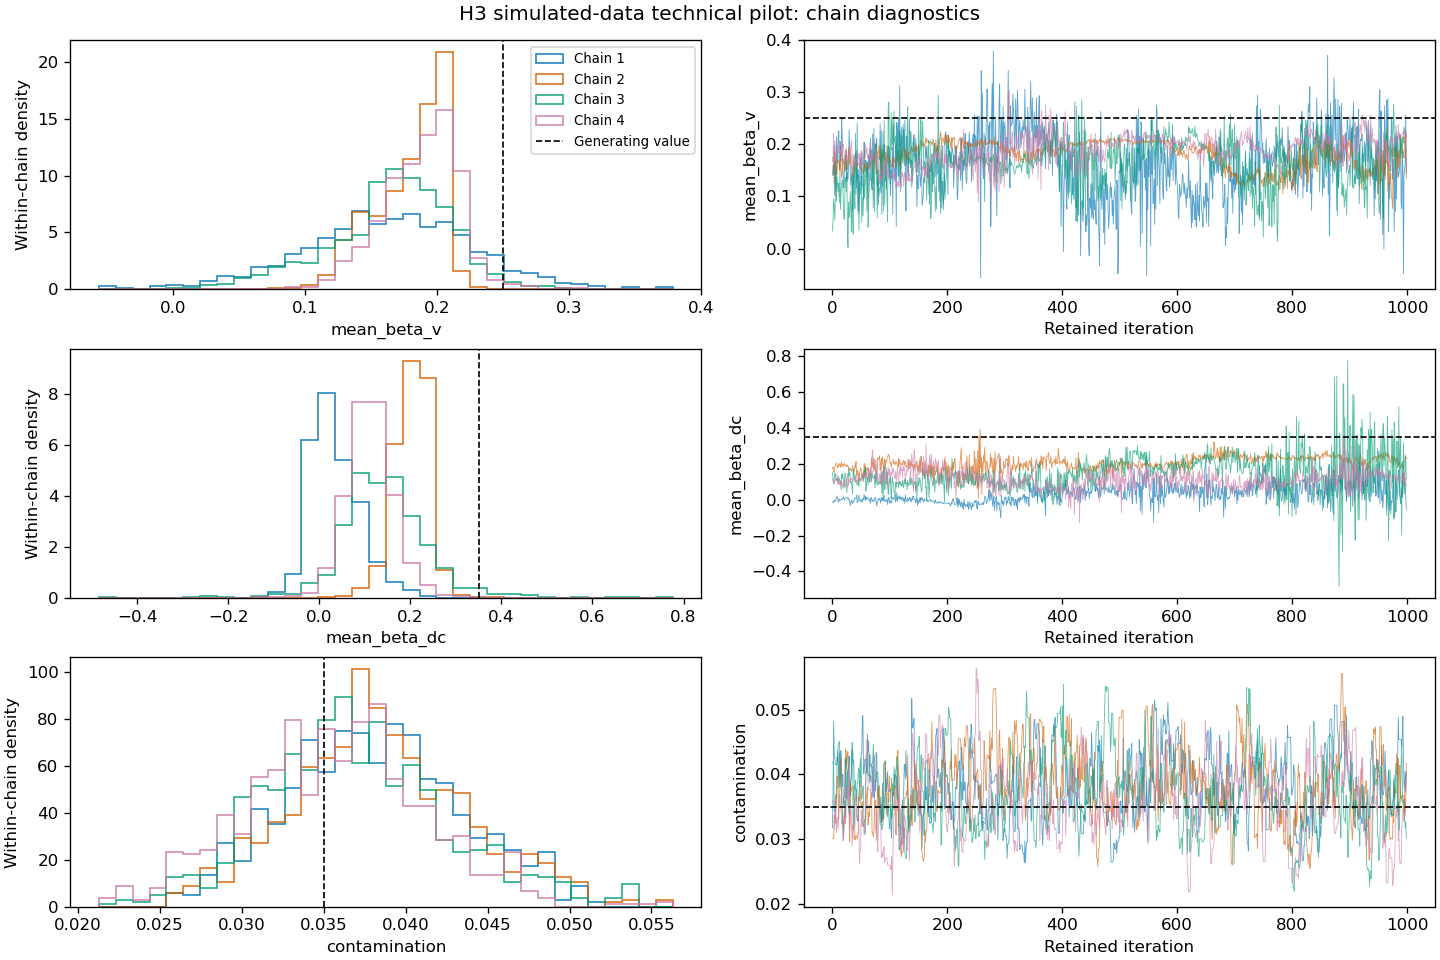

Saved local pilot draws: Output/hddm/matching/mechanism_pilot_20261024.npz


In [5]:
# Centered hierarchical sampler: exact normal conditional for group means;
# log-scale MH for half-normal SDs, adaptive multivariate subject blocks.
def run_chain(seed,model='H3',iterations=2000,burn=1000):
    rng=np.random.default_rng(seed);active=allowed(model);k=len(active);N=len(data)
    m=prior_mu.copy();m[active]+=rng.normal(0,.03,k)
    sig=scale_prior*.65
    theta=np.tile(m,(N,1));theta[:,active]+=rng.normal(size=(N,k))*.03
    for j in set(range(11))-set(active):m[j]=0;theta[:,j]=0;sig[j]=0
    lc=rng.normal(0,.03,2);eps=.05
    lls=np.array([subject_ll(th,C@lc,eps,x) for th,x in zip(theta,data)])
    assert np.isfinite(lls).all()
    cov=[np.eye(k)*.012**2 for _ in range(N)];history=[[] for _ in range(N)]
    scales=np.ones(N);accepted=np.zeros(N);window=np.zeros(N)
    samples=[];global_accept=np.zeros(3);eta=0.
    def norm_prior(th,mean,sd):return -.5*np.sum(((th[active]-mean[active])/sd[active])**2)
    for it in range(iterations):
        for i in range(N):
            cand=theta[i].copy();cand[active]+=rng.multivariate_normal(np.zeros(k),cov[i])*scales[i]
            try:newll=subject_ll(cand,C@lc,eps,data[i])
            except (ArithmeticError,OverflowError):newll=-np.inf
            ratio=newll-lls[i]+norm_prior(cand,m,sig)-norm_prior(theta[i],m,sig)
            if np.log(rng.random())<ratio:
                theta[i]=cand;lls[i]=newll;accepted[i]+=1;window[i]+=1
            if it<burn:
                history[i].append(theta[i,active].copy())
                if it>=199 and (it+1)%50==0:
                    cov[i]=np.cov(np.asarray(history[i]).T)*(2.38**2/k)+np.eye(k)*1e-6
                if (it+1)%50==0:
                    scales[i]*=np.exp(.3*(window[i]/50-.25));window[i]=0
        # Conditional group means under the declared Normal hyperprior.
        var=1/(N/sig[active]**2+1/prior_sd[active]**2)
        mean=var*(theta[:,active].sum(axis=0)/sig[active]**2+prior_mu[active]/prior_sd[active]**2)
        m[active]=rng.normal(mean,np.sqrt(var))
        for j in active:
            old=np.log(sig[j]);new=old+rng.normal(0,.15);sn=np.exp(new)
            ss=np.sum((theta[:,j]-m[j])**2)
            def logscale(s,log_s):return -(N-1)*log_s-ss/(2*s*s)-s*s/(2*scale_prior[j]**2)
            if np.log(rng.random())<logscale(sn,new)-logscale(sig[j],old):sig[j]=sn
        for j in range(2):
            proposal=lc.copy();proposal[j]+=rng.normal(0,.018)
            lnew=np.array([subject_ll(th,C@proposal,eps,x) for th,x in zip(theta,data)])
            ratio=lnew.sum()-lls.sum()-(proposal[j]**2-lc[j]**2)/(2*.25**2)
            if np.log(rng.random())<ratio:lc=proposal;lls=lnew;global_accept[j]+=1
        newlogit=logit(eps)+rng.normal(0,.12);ep=expit(newlogit)
        lnew=np.array([subject_ll(th,C@lc,ep,x) for th,x in zip(theta,data)])
        # Beta(1,19) with the logit-transform Jacobian.
        ratio=lnew.sum()-lls.sum()+np.log(ep)+19*np.log1p(-ep)-np.log(eps)-19*np.log1p(-eps)
        if np.log(rng.random())<ratio:eps=ep;lls=lnew;global_accept[2]+=1
        ni=sum(x['illegal'] for x in data);nt=sum(x['n'] for x in data)
        eta=rng.beta(1+ni,999+nt-ni)
        if it>=burn:samples.append(np.r_[m[active],sig[active],lc,eps,eta,theta[:,active].ravel()])
    return np.asarray(samples),accepted/iterations,global_accept/iterations

from multiprocessing import get_context
seeds=[2026102511,2026102521,2026102531,2026102541]
start=time.perf_counter()
with get_context('fork').Pool(2) as pool:
    chains=pool.map(run_chain,seeds)
elapsed=time.perf_counter()-start
draws=np.stack([c[0] for c in chains])
labels=['mean_'+x for x in names]+['sd_'+x for x in names]+['relation_coef1','relation_coef2','contamination','illegal_rate']+[f'subject_{sub}_{x}' for sub in pilot_subjects for x in names]
assert draws.shape==(4,1000,len(labels))
idata=az.from_dict(posterior={name:draws[:,:,j] for j,name in enumerate(labels)})
diagnostics=az.summary(idata,round_to='none',hdi_prob=.95)
print('Elapsed seconds:',elapsed)
print('Subject-block acceptance by chain:',[c[1].round(3).tolist() for c in chains])
print('Global acceptance by chain:',[c[2].round(3).tolist() for c in chains])
display(diagnostics.loc[['mean_beta_v','mean_beta_dc','sd_beta_v','sd_beta_dc','contamination','relation_coef1','relation_coef2']])
print('All-parameter max Rhat:',diagnostics.r_hat.max(),'min bulk ESS:',diagnostics.ess_bulk.min(),'min tail ESS:',diagnostics.ess_tail.min())
truth_flat=np.r_[truth_mu,truth_sd,truth_lcoef,truth_eps,truth_eta,truth_theta.ravel()]
recovery=pd.DataFrame({'true':truth_flat,'posterior_mean':draws.mean(axis=(0,1)),
                       'q025':np.quantile(draws,.025,axis=(0,1)),'q975':np.quantile(draws,.975,axis=(0,1))},index=labels)
recovery['error']=recovery.posterior_mean-recovery.true
display(recovery.loc[['mean_beta_v','mean_beta_dc','sd_beta_v','sd_beta_dc','contamination']])
print('Pooled group-effect posterior correlation (requires convergence):',np.corrcoef(draws[:,:,6].ravel(),draws[:,:,10].ravel())[0,1])
plot_pilot_trace(draws,labels,truth_flat)
plt.show()
out=ROOT/'Output/hddm/matching/mechanism_pilot_20261024.npz'
assert not out.exists(),'Preserve previous pilot draws; choose an explicitly new version for a rerun.'
np.savez_compressed(out,draws=draws,labels=np.asarray(labels),truth=truth_flat,seeds=np.asarray(seeds),
                    generated_deadlines=truth_deadlines,subject_ids=np.asarray(pilot_subjects))
print('Saved local pilot draws:',out.relative_to(ROOT))


## 推断限制与下一步条件

本试验若未达到多链诊断标准，后验均值、区间与相关只用于定位估计器问题，不能作为参数恢复结论。即使通过，单次 6 人试验仍不能估计区间覆盖率或模型误判率。没有运行 H0–H3 交叉拟合，因此不生成虚假的模型恢复混淆矩阵；也没有真实数据模型排序、LOO 或 PPC。

截止不确定性和污染分布是工作假设。模型恢复需至少扩展到 42 人、全部候选生成/拟合组合、弱效应和多次重复；并对难度参照、先验、截止范围、污染支持区间进行敏感性分析。当前真实数据的关键快速分布失配仍未解决，技术恢复本身不会证明模型充分。

参考：[原方案](matching_model_design.md)、[科学审查](matching_mechanism_audit.ipynb)、[Stan：Wiener 删失模型](https://mc-stan.org/docs/stan-users-guide/wiener_diffusion_model.html)、[Pan et al. (2025)](https://doi.org/10.1177/25152459241298700)、[邬思宇等（2026）](https://chinaxiv.org/abs/202604.00323)。


## 第二次技术试验：交替参数化更新

首轮四链未收敛（最大 R̂ 2.189；最小 bulk ESS 5.16），不能用于恢复推断。保持同一模拟数据、层级模型和先验，增加保持标准化个体偏差不变的群体均值/尺度联合更新；这只是采样算法的改变。独立四链各 10,000 次，其中前 5,000 次预热。首轮样本单独保留。


Elapsed seconds: 645.4237566550146
Subject-block acceptance by chain: [[0.261, 0.239, 0.246, 0.255, 0.247, 0.245], [0.262, 0.264, 0.306, 0.276, 0.272, 0.276], [0.262, 0.271, 0.283, 0.285, 0.278, 0.274], [0.298, 0.288, 0.289, 0.296, 0.309, 0.286]]
Global acceptance by chain: [[0.646, 0.626, 0.74], [0.65, 0.63, 0.738], [0.656, 0.634, 0.741], [0.652, 0.63, 0.747]]


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mean_beta_v,0.275977,0.070140,0.131535,0.408076,0.003526,0.002520,393.763435,837.324301,1.007786
mean_beta_dc,0.356305,0.176265,0.009406,0.701234,0.008653,0.006372,399.372914,2153.483162,1.016242
sd_beta_v,0.075213,0.055392,0.000648,0.181488,0.004602,0.003260,100.262618,96.294298,1.038851
sd_beta_dc,0.341688,0.142677,0.036247,0.606037,0.011168,0.007911,157.583168,84.170084,1.020096
contamination,0.037421,0.005399,0.026796,0.047801,0.000174,0.000123,956.990240,2051.772701,1.002581
relation_coef1,-0.060003,0.049675,-0.157533,0.034790,0.000929,0.000658,2855.198843,3843.409527,1.000592
relation_coef2,-0.152260,0.045745,-0.239016,-0.058795,0.000828,0.000593,3055.909394,3832.772532,1.000205


All-parameter max Rhat: 1.0760783585166718 min bulk ESS: 59.204787482349985 min tail ESS: 70.11389208229


,true,posterior_mean,q025,q975,error
mean_beta_v,0.250,0.275977,0.138022,0.416361,0.025977
mean_beta_dc,0.350,0.356305,-0.006687,0.687021,0.006305
sd_beta_v,0.100,0.075213,0.005308,0.215640,-0.024787
sd_beta_dc,0.120,0.341688,0.057406,0.633577,0.221688
contamination,0.035,0.037421,0.027196,0.048373,0.002421


Pooled group-effect posterior correlation (requires convergence): 0.06260667194212961


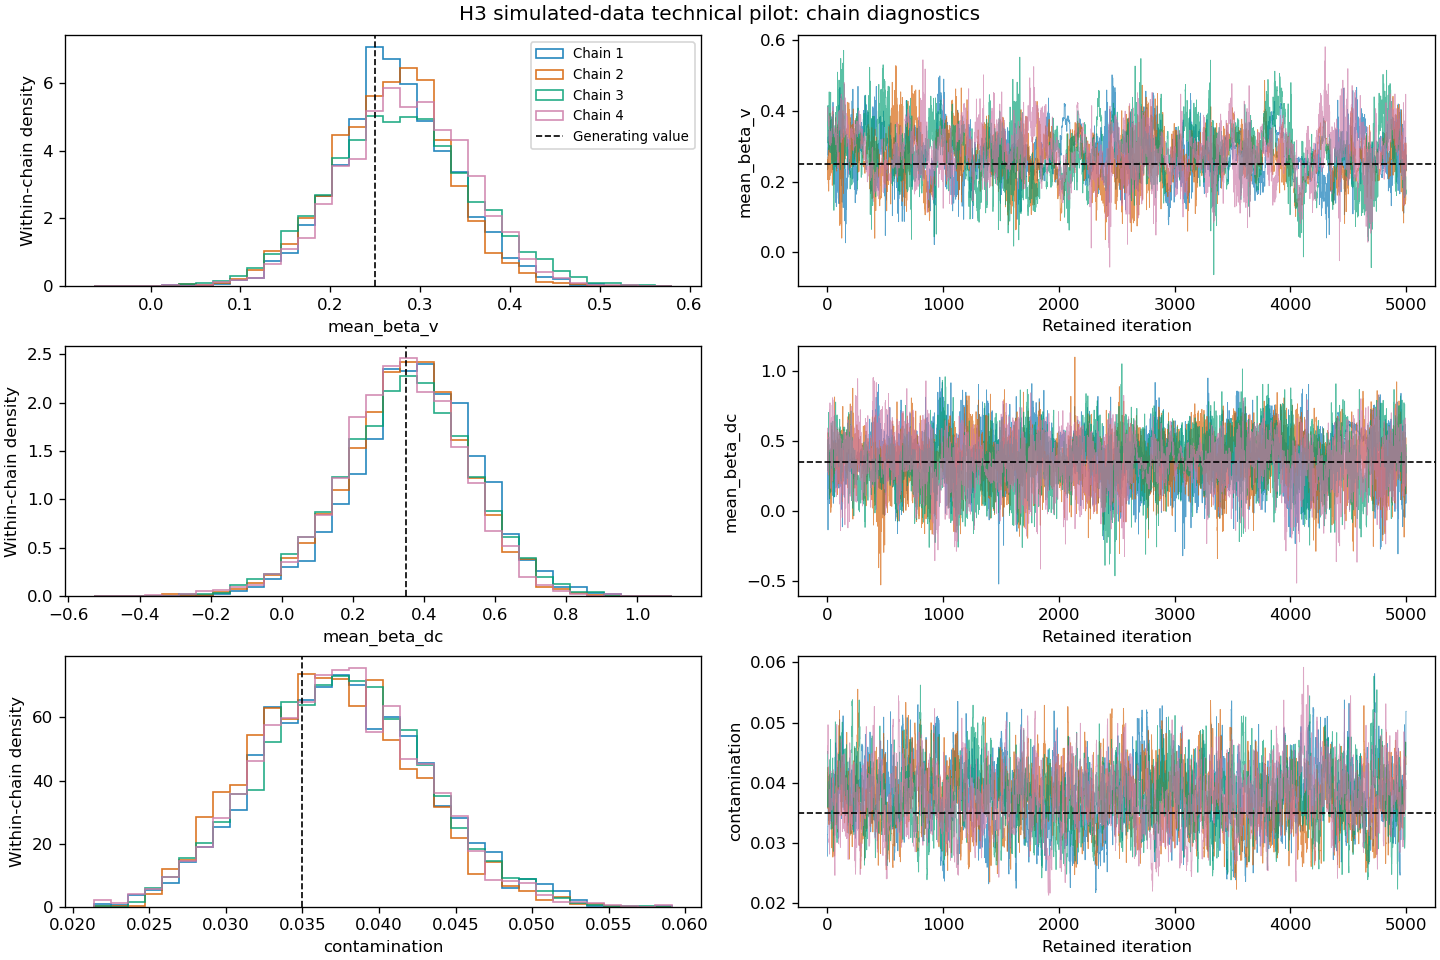

Saved local pilot draws: Output/hddm/matching/mechanism_pilot_interwoven_20261024.npz


In [5]:
# Centered hierarchical sampler: exact normal conditional for group means;
# log-scale MH for half-normal SDs, adaptive multivariate subject blocks.
def run_interwoven(seed,model='H3',iterations=10000,burn=5000):
    rng=np.random.default_rng(seed);active=allowed(model);k=len(active);N=len(data)
    m=prior_mu.copy();m[active]+=rng.normal(0,.03,k)
    sig=scale_prior*.65
    theta=np.tile(m,(N,1));theta[:,active]+=rng.normal(size=(N,k))*.03
    for j in set(range(11))-set(active):m[j]=0;theta[:,j]=0;sig[j]=0
    lc=rng.normal(0,.03,2);eps=.05
    lls=np.array([subject_ll(th,C@lc,eps,x) for th,x in zip(theta,data)])
    assert np.isfinite(lls).all()
    cov=[np.eye(k)*.012**2 for _ in range(N)];history=[[] for _ in range(N)]
    scales=np.ones(N);accepted=np.zeros(N);window=np.zeros(N)
    samples=[];global_accept=np.zeros(3);eta=0.
    def norm_prior(th,mean,sd):return -.5*np.sum(((th[active]-mean[active])/sd[active])**2)
    for it in range(iterations):
        for i in range(N):
            cand=theta[i].copy();cand[active]+=rng.multivariate_normal(np.zeros(k),cov[i])*scales[i]
            try:newll=subject_ll(cand,C@lc,eps,data[i])
            except (ArithmeticError,OverflowError):newll=-np.inf
            ratio=newll-lls[i]+norm_prior(cand,m,sig)-norm_prior(theta[i],m,sig)
            if np.log(rng.random())<ratio:
                theta[i]=cand;lls[i]=newll;accepted[i]+=1;window[i]+=1
            if it<burn:
                history[i].append(theta[i,active].copy())
                if it>=199 and (it+1)%50==0:
                    cov[i]=np.cov(np.asarray(history[i]).T)*(2.38**2/k)+np.eye(k)*1e-6
                if (it+1)%50==0:
                    scales[i]*=np.exp(.3*(window[i]/50-.25));window[i]=0
        # Conditional group means under the declared Normal hyperprior.
        var=1/(N/sig[active]**2+1/prior_sd[active]**2)
        mean=var*(theta[:,active].sum(axis=0)/sig[active]**2+prior_mu[active]/prior_sd[active]**2)
        m[active]=rng.normal(mean,np.sqrt(var))
        for j in active:
            old=np.log(sig[j]);new=old+rng.normal(0,.15);sn=np.exp(new)
            ss=np.sum((theta[:,j]-m[j])**2)
            def logscale(s,log_s):return -(N-1)*log_s-ss/(2*s*s)-s*s/(2*scale_prior[j]**2)
            if np.log(rng.random())<logscale(sn,new)-logscale(sig[j],old):sig[j]=sn
        # Interweave non-centered hyperparameter moves, keeping standardized
        # individual deviations fixed. Target uses hyperpriors + likelihood;
        # the individual Normal density/Jacobian cancel in this coordinate system.
        if it%5==0:
            for j in active:
                standardized=(theta[:,j]-m[j])/sig[j]
                mn=m[j]+rng.normal(0,.035)
                logs=np.log(sig[j])+rng.normal(0,.18);sn=np.exp(logs)
                proposal_theta=theta.copy();proposal_theta[:,j]=mn+sn*standardized
                try:lnew=np.array([subject_ll(th,C@lc,eps,x) for th,x in zip(proposal_theta,data)])
                except (ArithmeticError,OverflowError):lnew=np.full(N,-np.inf)
                ratio=lnew.sum()-lls.sum()
                ratio+=-.5*((mn-prior_mu[j])**2-(m[j]-prior_mu[j])**2)/prior_sd[j]**2
                ratio+=-.5*(sn**2-sig[j]**2)/scale_prior[j]**2+logs-np.log(sig[j])
                if np.log(rng.random())<ratio:
                    theta=proposal_theta;m[j]=mn;sig[j]=sn;lls=lnew
        for j in range(2):
            proposal=lc.copy();proposal[j]+=rng.normal(0,.06)
            lnew=np.array([subject_ll(th,C@proposal,eps,x) for th,x in zip(theta,data)])
            ratio=lnew.sum()-lls.sum()-(proposal[j]**2-lc[j]**2)/(2*.25**2)
            if np.log(rng.random())<ratio:lc=proposal;lls=lnew;global_accept[j]+=1
        newlogit=logit(eps)+rng.normal(0,.12);ep=expit(newlogit)
        lnew=np.array([subject_ll(th,C@lc,ep,x) for th,x in zip(theta,data)])
        # Beta(1,19) with the logit-transform Jacobian.
        ratio=lnew.sum()-lls.sum()+np.log(ep)+19*np.log1p(-ep)-np.log(eps)-19*np.log1p(-eps)
        if np.log(rng.random())<ratio:eps=ep;lls=lnew;global_accept[2]+=1
        ni=sum(x['illegal'] for x in data);nt=sum(x['n'] for x in data)
        eta=rng.beta(1+ni,999+nt-ni)
        if it>=burn:samples.append(np.r_[m[active],sig[active],lc,eps,eta,theta[:,active].ravel()])
    return np.asarray(samples),accepted/iterations,global_accept/iterations

from multiprocessing import get_context
seeds=[2026102611,2026102621,2026102631,2026102641]
start=time.perf_counter()
with get_context('fork').Pool(2) as pool:
    chains=pool.map(run_interwoven,seeds)
elapsed=time.perf_counter()-start
draws=np.stack([c[0] for c in chains])
labels=['mean_'+x for x in names]+['sd_'+x for x in names]+['relation_coef1','relation_coef2','contamination','illegal_rate']+[f'subject_{sub}_{x}' for sub in pilot_subjects for x in names]
assert draws.shape==(4,5000,len(labels))
idata=az.from_dict(posterior={name:draws[:,:,j] for j,name in enumerate(labels)})
diagnostics=az.summary(idata,round_to='none',hdi_prob=.95)
print('Elapsed seconds:',elapsed)
print('Subject-block acceptance by chain:',[c[1].round(3).tolist() for c in chains])
print('Global acceptance by chain:',[c[2].round(3).tolist() for c in chains])
display(diagnostics.loc[['mean_beta_v','mean_beta_dc','sd_beta_v','sd_beta_dc','contamination','relation_coef1','relation_coef2']])
print('All-parameter max Rhat:',diagnostics.r_hat.max(),'min bulk ESS:',diagnostics.ess_bulk.min(),'min tail ESS:',diagnostics.ess_tail.min())
truth_flat=np.r_[truth_mu,truth_sd,truth_lcoef,truth_eps,truth_eta,truth_theta.ravel()]
recovery=pd.DataFrame({'true':truth_flat,'posterior_mean':draws.mean(axis=(0,1)),
                       'q025':np.quantile(draws,.025,axis=(0,1)),'q975':np.quantile(draws,.975,axis=(0,1))},index=labels)
recovery['error']=recovery.posterior_mean-recovery.true
display(recovery.loc[['mean_beta_v','mean_beta_dc','sd_beta_v','sd_beta_dc','contamination']])
print('Pooled group-effect posterior correlation (requires convergence):',np.corrcoef(draws[:,:,6].ravel(),draws[:,:,10].ravel())[0,1])
plot_pilot_trace(draws,labels,truth_flat)
plt.show()
out=ROOT/'Output/hddm/matching/mechanism_pilot_interwoven_20261024.npz'
assert not out.exists(),'Preserve previous pilot draws; choose an explicitly new version for a rerun.'
np.savez_compressed(out,draws=draws,labels=np.asarray(labels),truth=truth_flat,seeds=np.asarray(seeds),
                    generated_deadlines=truth_deadlines,subject_ids=np.asarray(pilot_subjects))
print('Saved local pilot draws:',out.relative_to(ROOT))


## 额外数值验证与两轮诊断比较


In [4]:
rng=np.random.default_rng(2026102701)
errors=[];failures=[]
for i in range(300):
    m=rng.normal(prior_mu,prior_sd);sd=abs(rng.normal(0,scale_prior));th=rng.normal(m,sd)
    lam=C@rng.normal(0,.25,2); cond=list(X)[i%4];stim=i%2;rel=list(relation_index)[i%3]
    a,t,z,mu=unpack(th,cond,stim,rel,lam); D=rng.uniform(1.,1.2)
    try:
        analytic=survival(np.array([D]),mu,a,z,t)[0]
        numeric=1. if D<=t else 1-quad(lambda rt:sum(hddm.wfpt.pdf_array(np.array([rt,-rt]),mu,0.,a,z,0.,t,0.,err=1e-8)),t,D,epsabs=1e-9,limit=200)[0]
        errors.append(abs(analytic-numeric))
        if abs(analytic-numeric)>1e-6:failures.append([i,a,t,z,mu,D,analytic,numeric])
    except Exception as ex:failures.append([i,str(ex),a,t,z,mu,D])
print('PRIOR SUPPORT CHECK',len(errors),'MAX ERROR',max(errors),'FAILURES',failures)

assert not failures

# Numerical checks use nonconverged draws only as numerical test locations.
# They are not posterior sensitivity estimates.
check_draws=np.load(ROOT/'Output/hddm/matching/mechanism_pilot_20261024.npz')['draws']
rows=[]
for width in [.001,1/60,1/30]:
    errs=[]
    for ch in range(4):
        for it in [0,250,500,750,999]:
            vec=check_draws[ch,it]; th=vec[26:].reshape(6,11);lc=vec[22:24];eps=vec[24]
            for theta,x in zip(th,data):
                l7=subject_ll(theta,C@lc,eps,x,width=width,nquad=7)
                l61=subject_ll(theta,C@lc,eps,x,width=width,nquad=61)
                errs.append(abs(l7-l61))
    rows.append([width,len(errs),max(errs)])
print('WIDER DEADLINE NUMERICS',rows)
assert max(x[2] for x in rows)<1e-4

comparison=[]
for label,file in [('centered','mechanism_pilot_20261024.npz'),('interwoven','mechanism_pilot_interwoven_20261024.npz')]:
    archive=np.load(ROOT/'Output/hddm/matching'/file)
    labels_saved=archive['labels'].tolist(); arr=archive['draws']
    ids=az.from_dict(posterior={name:arr[:,:,j] for j,name in enumerate(labels_saved)})
    dg=az.summary(ids,round_to='none',hdi_prob=.95)
    comparison.append([label,arr.shape[1],dg.r_hat.max(),dg.ess_bulk.min(),dg.ess_tail.min(),dg.loc['mean_beta_v','r_hat'],dg.loc['mean_beta_dc','r_hat']])
    if label=='interwoven':display(dg.sort_values('r_hat',ascending=False).head(10))
display(pd.DataFrame(comparison,columns=['sampler','retained_per_chain','max_Rhat','min_bulk_ESS','min_tail_ESS','beta_v_Rhat','beta_dc_Rhat']))


PRIOR SUPPORT CHECK 300 MAX ERROR 5.087925445540487e-10 FAILURES []


WIDER DEADLINE NUMERICS [[0.001, 120, 2.842170943040401e-14], [0.016666666666666666, 120, 5.684341886080802e-14], [0.03333333333333333, 120, 1.9525714378687553e-11]]


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sd_v_other_contrast,0.110191,0.074333,0.002507,0.248826,0.008910,0.006327,59.204787,70.113892,1.076078
sd_dc_other_contrast,0.131672,0.093021,0.003620,0.305320,0.007609,0.005391,83.195004,94.770647,1.060786
subject_7323_beta_dc,0.457699,0.219318,0.050664,0.883796,0.023836,0.016913,83.701938,204.057072,1.058917
subject_7328_log_a,-0.058948,0.026401,-0.114413,-0.010964,0.002194,0.001613,137.820239,349.559902,1.057269
subject_7328_dc_other,-0.147974,0.139751,-0.444037,0.109232,0.016169,0.011478,75.094209,373.258438,1.056184
subject_7323_dc_other_contrast,0.058527,0.166191,-0.236193,0.424018,0.016945,0.012019,94.959241,324.853343,1.055725
subject_7323_logit_z,0.174362,0.046951,0.079537,0.260463,0.004181,0.002963,126.539468,305.781937,1.054158
subject_7328_dc_intercept,0.083837,0.104634,-0.135086,0.277921,0.011557,0.008201,79.597420,272.258113,1.054123
subject_7325_logit_z,0.195752,0.043252,0.106101,0.278518,0.004417,0.003133,98.367118,371.986395,1.054113
subject_7307_v_intercept,0.710039,0.069267,0.581921,0.848649,0.006803,0.004824,103.000772,341.717532,1.051927


,sampler,retained_per_chain,max_Rhat,min_bulk_ESS,min_tail_ESS,beta_v_Rhat,beta_dc_Rhat
0,centered,1000,2.189011,5.157326,11.950793,1.073873,1.558286
1,interwoven,5000,1.076078,59.204787,70.113892,1.007786,1.016242


## 本轮结论

一致的条件观察模型已实现，并通过列出的密度积分、事件概率归一化、模拟 CDF 及截止积分数值检查。三类反应均有明确概率，未把非法按键强制解释为超时。是否符合真实实验仍需经验检验，特别是截止代理的测量误差、污染支持范围，以及无反应是否全部来自删失。

两轮仅拟合同一个 6 人模拟数据集。首轮最大 R̂=2.189、最小 bulk ESS=5.16；第二轮四链各 10,000 次、预热 5,000 次，最大 R̂=1.076、最小 bulk ESS=59.20、最小 tail ESS=70.11。第二轮群体 β_v 与 β_dc 的 R̂ 分别为 1.0078 和 1.0162，bulk ESS 分别为 393.8 和 399.4。**整体验收未通过**。最差诊断出现在 Other 内 v 对比的群体标准差（R̂=1.076、bulk ESS=59.2），另外仍有个体 dc、z、a 等参数的混合不足；不能只依据两个群体目标效应接近阈值而忽略干扰参数。第二轮同时改变更新方式及采样预算，不能把改善全部归因于某一算法步骤。

后验均值、区间和相关只作为技术诊断展示，不能据此报告可靠的偏差、覆盖率或机制恢复。单数据集本来也不能估计覆盖率；当前没有模型恢复混淆矩阵、真实数据参数估计、LOO 或正式 PPC。6 人技术试验的困难不能外推为 42 人实验缺乏识别能力。

当前证据支持三点：在固定共同难度参照及观察假设下，可定义一个一致的层级估计问题；参照不受约束时，v 与 dc 的分解仍有精确等价；采样精度和真实数据的分布充分性均尚待解决。下一道验收应是改进估计器并核查先验预测，随后在多个已知真值数据集上开展包含弱效应、H0 及完整 42 人设计的恢复。不能直接进入真实数据模型排名。

由于截止是被试内共享的潜变量，积分后的联合似然不能简单拆成独立试次用于 PSIS-LOO。需先明确预测新被试或现有被试的新试次，并相应处理留出单位及潜变量。

参考：[Hu et al. (2020)](https://doi.org/10.1525/collabra.301)、[Pan et al. (2025)](https://doi.org/10.1177/25152459241298700)、[邬思宇等（2026，预印本）](https://chinaxiv.org/abs/202604.00323)、[Wiener 联合选择—RT 密度说明](https://mc-stan.org/docs/stan-users-guide/wiener_diffusion_model.html)。技术试验的扩展观察模型与采样器是本轮新实现，不是对文献现成模型已验证性质的直接继承。


## 第三次技术试验：尺度切片与校正联合提议

保持既定先验、关系难度零和约束和观察似然。群体尺度采用对数坐标上的切片更新；个体参数的固定局部二次近似仅构造 Student-t 提议，使用完整原始似然及精确 Metropolis–Hastings 比率校正，不把 Laplace 近似作为后验。保留部分局部随机游走和交替参数化更新。已有样本只用于构造提议，不改变目标分布。四链各 5,000 次，前 1,500 次不用于诊断。


In [4]:

from scipy.optimize import minimize

def build_proposals(data, active, starts, lc_ref, eps_ref):
    # Fixed quadratic approximations construct proposals ONLY. MH always uses
    # the original joint likelihood and unchanged priors.
    result=[]; k=len(active)
    for i,x in enumerate(data):
        anchor=starts[i].copy()
        anchor[list(set(range(11))-set(active))]=0
        def ll(y):
            th=anchor.copy();th[active]=y
            try:return subject_ll(th,C@lc_ref,eps_ref,x)
            except (ArithmeticError,OverflowError):return -np.inf
        y0=anchor[active]
        opt=minimize(lambda y:-ll(y)+.5*np.sum((y-y0)**2),y0,method='BFGS',options={'maxiter':150,'gtol':.005})
        center=opt.x if np.isfinite(opt.fun) else y0
        h=1e-4; eye=np.eye(k)*h; f0=ll(center)
        grad=np.array([(ll(center+e)-ll(center-e))/(2*h) for e in eye])
        H=np.zeros((k,k))
        for j in range(k):
            H[j,j]=-(ll(center+eye[j])-2*f0+ll(center-eye[j]))/h**2
            for l in range(j):
                H[j,l]=H[l,j]=-(ll(center+eye[j]+eye[l])-ll(center+eye[j]-eye[l])-ll(center-eye[j]+eye[l])+ll(center-eye[j]-eye[l]))/(4*h*h)
        eig,U=np.linalg.eigh(H);H=(U*np.maximum(eig,.01))@U.T
        assert np.isfinite(H).all() and np.isfinite(grad).all()
        result.append((H,H@center+grad,center))
        print('proposal',i+1,'of',len(data),'evaluations',opt.nfev,'min curvature',float(eig.min()),flush=True)
    return result

def slice_sd(current,ss,N,scale,rng):
    def target(x):
        if abs(x)>350:return -np.inf
        s=np.exp(x)
        return -(N-1)*x-ss/(2*s*s)-s*s/(2*scale*scale)
    x=np.log(current); height=target(x)+np.log(rng.random());w=.7
    L=x-w*rng.random();R=L+w;J=rng.integers(60);K=59-J
    while J>0 and target(L)>height:L-=w;J-=1
    while K>0 and target(R)>height:R+=w;K-=1
    for _ in range(1000):
        y=rng.uniform(L,R)
        if target(y)>=height:return np.exp(y)
        if y<x:L=y
        else:R=y
    raise RuntimeError('Scale slice bracket failed')

def run_laplace_chain(seed,model='H3',iterations=5000,burn=1500,global_correction=False,dispersed=False,progress_path=None,collapsed=False,initial_state=None):
    rng=np.random.default_rng(seed);active=allowed(model);k=len(active);N=len(data)
    m=prior_mu.copy();m[active]+=rng.normal(0,.1,k)
    sig=scale_prior*rng.uniform(.4,1.2,len(scale_prior))
    theta=np.tile(m,(N,1))
    for j in set(range(11))-set(active):m[j]=0;sig[j]=0;theta[:,j]=0
    lc=lc_reference+rng.normal(0,.02,2);eps=float(expit(logit(eps_reference)+rng.normal(0,.2)))
    for i,(H,b,center) in enumerate(proposals):
        theta[i,active]=center
        if dispersed:
            Q=H+np.diag(1/sig[active]**2)
            theta[i,active]+=2*np.linalg.solve(np.linalg.cholesky(Q).T,rng.normal(size=k))
    if initial_state is not None:
        state=np.asarray(initial_state)
        assert len(state)==2*k+4+N*k
        m[active]=state[:k];sig[active]=state[k:2*k]
        lc=state[2*k:2*k+2].copy();eps=float(state[2*k+2])
        theta[:,active]=state[2*k+4:].reshape(N,k)
    lls=np.array([subject_ll(th,C@lc,eps,x) for th,x in zip(theta,data)])
    assert np.isfinite(lls).all()
    samples=[];accepted=np.zeros(N);ga=np.zeros(3);nu=7;collapsed_accept=np.zeros(k)
    ni=sum(x['illegal'] for x in data);nt=sum(x['n'] for x in data)
    for it in range(iterations):
        for i,(H,b,center) in enumerate(proposals):
            prec=1/sig[active]**2
            Q=H+np.diag(prec);chol=np.linalg.cholesky(Q)
            adjustment=proposal_cross[i]@(np.r_[lc,logit(eps)]-np.r_[lc_reference,logit(eps_reference)]) if global_correction else 0.
            qm=np.linalg.solve(Q,b+adjustment+prec*m[active])
            # Mostly independence Student-t; occasional symmetric local move.
            independent=rng.random()<.85
            cand=theta[i].copy()
            if independent:cand[active]=qm+np.linalg.solve(chol.T,rng.normal(size=k))/np.sqrt(rng.chisquare(nu)/nu)
            else:cand[active]+=np.linalg.solve(chol.T,rng.normal(size=k))*(2.38/np.sqrt(k))
            try:newll=subject_ll(cand,C@lc,eps,data[i])
            except (ArithmeticError,OverflowError):newll=-np.inf
            ratio=newll-lls[i]-.5*np.sum(((cand[active]-m[active])**2-(theta[i,active]-m[active])**2)*prec)
            if independent:
                old=theta[i,active]-qm;new=cand[active]-qm
                ratio+=-.5*(nu+k)*(np.log1p(old@Q@old/nu)-np.log1p(new@Q@new/nu))
            if np.log(rng.random())<ratio:theta[i]=cand;lls[i]=newll;accepted[i]+=1
        var=1/(N/sig[active]**2+1/prior_sd[active]**2)
        mean=var*(theta[:,active].sum(axis=0)/sig[active]**2+prior_mu[active]/prior_sd[active]**2)
        m[active]=rng.normal(mean,np.sqrt(var))
        for j in active:sig[j]=slice_sd(sig[j],np.sum((theta[:,j]-m[j])**2),N,scale_prior[j],rng)
        if it%5==0:
            if collapsed:
                for pos,j in enumerate(active):
                    thactive=theta[:,active]
                    h=np.array([item[0][pos,pos] for item in proposals])
                    dg=np.r_[lc,logit(eps)]-np.r_[lc_reference,logit(eps_reference)]
                    y=np.array([(bb[pos]+(proposal_cross[i][pos]@dg if global_correction else 0.)-H[pos]@thactive[i]+H[pos,pos]*theta[i,j])/H[pos,pos] for i,(H,bb,_) in enumerate(proposals)])
                    mn,sn,tj=surrogate_hyper_draw(y,h,m[j],sig[j],prior_mu[j],prior_sd[j],scale_prior[j],rng,bool(rng.integers(2)))
                    tt=theta.copy();tt[:,j]=tj
                    try:llnew=np.array([subject_ll(th,C@lc,eps,x) for th,x in zip(tt,data)])
                    except (ArithmeticError,OverflowError):llnew=np.full(N,-np.inf)
                    # Surrogate transition is reversible under surrogate likelihood
                    # times the SAME priors. Hence only likelihood corrections remain.
                    ratio=llnew.sum()-lls.sum()+.5*np.sum(h*((tj-y)**2-(theta[:,j]-y)**2))
                    if np.log(rng.random())<ratio:
                        theta=tt;m[j]=mn;sig[j]=sn;lls=llnew;collapsed_accept[pos]+=1
            else:
                for j in active:
                    u=(theta[:,j]-m[j])/sig[j];mn=m[j]+rng.normal(0,.035)
                    logs=np.log(sig[j])+rng.normal(0,.5);sn=np.exp(logs)
                    tt=theta.copy();tt[:,j]=mn+sn*u
                    try:llnew=np.array([subject_ll(th,C@lc,eps,x) for th,x in zip(tt,data)])
                    except (ArithmeticError,OverflowError):llnew=np.full(N,-np.inf)
                    ratio=llnew.sum()-lls.sum()-.5*((mn-prior_mu[j])**2-(m[j]-prior_mu[j])**2)/prior_sd[j]**2
                    ratio+=-.5*(sn*sn-sig[j]**2)/scale_prior[j]**2+logs-np.log(sig[j])
                    if np.log(rng.random())<ratio:theta=tt;m[j]=mn;sig[j]=sn;lls=llnew
        for j in range(2):
            prop=lc.copy();prop[j]+=rng.normal(0,.08)
            llnew=np.array([subject_ll(th,C@prop,eps,x) for th,x in zip(theta,data)])
            ratio=llnew.sum()-lls.sum()-(prop[j]**2-lc[j]**2)/(2*.25**2)
            if np.log(rng.random())<ratio:lc=prop;lls=llnew;ga[j]+=1
        ep=float(expit(logit(eps)+rng.normal(0,.25)))
        llnew=np.array([subject_ll(th,C@lc,ep,x) for th,x in zip(theta,data)])
        ratio=llnew.sum()-lls.sum()+np.log(ep)+19*np.log1p(-ep)-np.log(eps)-19*np.log1p(-eps)
        if np.log(rng.random())<ratio:eps=ep;lls=llnew;ga[2]+=1
        eta=rng.beta(1+ni,999+nt-ni)
        if it>=burn:samples.append(np.r_[m[active],sig[active],lc,eps,eta,theta[:,active].ravel()])
        if (it+1)%1000==0:
            print('chain',seed,'iteration',it+1,flush=True)
            if progress_path:
                with open(progress_path,'a') as progress:progress.write(f'{seed} {it+1}/{iterations}\n')
    base=(np.asarray(samples),accepted/iterations,ga/iterations)
    return base+(collapsed_accept/len(range(0,iterations,5)),) if collapsed else base


proposal 1 of 6 evaluations 228 min curvature 12.56625482291102


proposal 2 of 6 evaluations 240 min curvature 10.062561145432376


proposal 3 of 6 evaluations 252 min curvature 14.764194367067285


proposal 4 of 6 evaluations 252 min curvature 13.995451946529734


proposal 5 of 6 evaluations 228 min curvature 10.312257490656547


...

5000

Elapsed seconds: 324.0329740989837
Acceptance: [[0.574, 0.552, 0.585, 0.551, 0.573, 0.579], [0.588, 0.555, 0.568, 0.548, 0.578, 0.575], [0.589, 0.548, 0.571, 0.556, 0.576, 0.575], [0.586, 0.563, 0.578, 0.559, 0.573, 0.575]]


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sd_dc_intercept,0.100862,0.077873,0.000100,0.246865,0.003234,0.002288,392.464711,397.545970,1.019278
sd_logit_z,0.056863,0.047385,0.000003,0.144010,0.001999,0.001414,258.935002,125.505285,1.013174
sd_dc_other_contrast,0.116654,0.091886,0.000043,0.293045,0.003974,0.002811,334.103832,271.400156,1.011756
mean_dc_other_contrast,-0.009166,0.124911,-0.248767,0.235497,0.005234,0.003703,566.262096,1272.430830,1.008906
sd_v_other_contrast,0.108119,0.077670,0.000102,0.254473,0.003075,0.002175,385.687384,248.518828,1.008337
subject_7325_dc_other_contrast,-0.057456,0.159944,-0.385424,0.239822,0.006268,0.004434,611.038124,1740.211663,1.007982
subject_7328_dc_other_contrast,-0.061156,0.163382,-0.410132,0.236687,0.006262,0.004430,624.339163,1756.541711,1.007295
subject_7304_dc_other_contrast,0.001597,0.151887,-0.306126,0.299736,0.005245,0.003710,807.496115,1839.547994,1.006997
subject_7325_dc_intercept,0.060144,0.098346,-0.133326,0.251711,0.003556,0.002516,748.287558,2260.774469,1.006766
subject_7323_logit_z,0.177273,0.046110,0.082557,0.258623,0.001769,0.001285,659.906202,1506.635181,1.006610


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mean_beta_v,0.279619,0.070548,0.143027,0.416902,0.002741,0.001939,651.564561,1379.905813,1.006085
mean_beta_dc,0.350338,0.174618,-0.012726,0.677872,0.003316,0.002345,2683.430303,6987.888236,1.000926
sd_beta_v,0.069480,0.055492,0.000334,0.177673,0.001913,0.001353,610.610081,482.909056,1.006330
sd_beta_dc,0.328957,0.146166,0.000335,0.569114,0.006304,0.004460,513.928449,194.341737,1.006249


All parameters: 1.0192775690757747 258.9350017515388 125.50528516748781


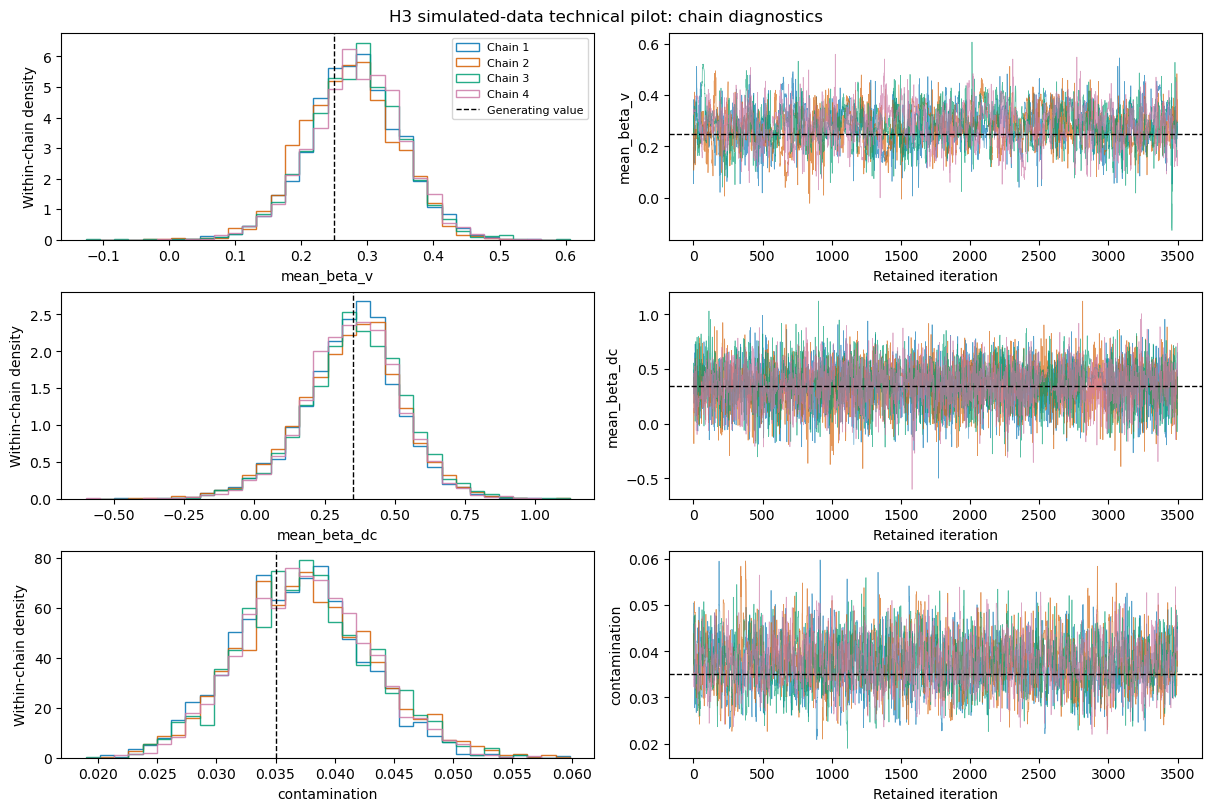

Saved /repo/02_reanalysis_2026/Output/hddm/matching/mechanism_pilot_slice_20261024.npz


In [5]:

# Reuse the SAME generated data; the earlier posterior only informs proposals.
# No generating nuisance parameters are supplied to the estimator.
previous=np.load(ROOT/'Output/hddm/matching/mechanism_pilot_interwoven_20261024.npz')
center=previous['draws'].mean(axis=(0,1))
lc_reference=center[22:24];eps_reference=center[24]
starts=center[26:].reshape(len(data),11)
proposals=build_proposals(data,allowed('H3'),starts,lc_reference,eps_reference)
seeds=[2026102811,2026102821,2026102831,2026102841]
from multiprocessing import get_context
start=time.perf_counter()
with get_context('fork').Pool(2) as pool:chains=pool.map(run_laplace_chain,seeds)
draws=np.stack([x[0] for x in chains]);labels=previous['labels'].tolist();truth_flat=previous['truth']
idata=az.from_dict(posterior={name:draws[:,:,j] for j,name in enumerate(labels)})
diagnostics=az.summary(idata,round_to='none',hdi_prob=.95)
print('Elapsed seconds:',time.perf_counter()-start)
print('Acceptance:',[x[1].round(3).tolist() for x in chains])
display(diagnostics.sort_values('r_hat',ascending=False).head(12))
display(diagnostics.loc[['mean_beta_v','mean_beta_dc','sd_beta_v','sd_beta_dc']])
print('All parameters:',diagnostics.r_hat.max(),diagnostics.ess_bulk.min(),diagnostics.ess_tail.min())
plot_pilot_trace(draws,labels,truth_flat);plt.show()
out=ROOT/'Output/hddm/matching/mechanism_pilot_slice_20261024.npz'
assert not out.exists()
np.savez_compressed(out,draws=draws,labels=np.asarray(labels),truth=truth_flat,seeds=np.asarray(seeds),generated_deadlines=truth_deadlines,subject_ids=np.asarray(pilot_subjects))
print('Saved',out)


## 完整 42 人设计的估计器检验

第三轮六人试验最大 R̂=1.0193、最小 bulk ESS=258.94、最小 tail ESS=125.51，改善明显但未完全通过。这里不继续调整六人数据，而生成独立的 42 人 × 600 次 H3 数据集。保持同一模型、先验和采样核；联合提议另纳入全局难度与污染参数的一阶曲率校正，仍使用精确 MH 校正。四链各 4,000 次，前 1,500 次不用于诊断，个体初值分散。所有生成真值仅用于事后对照，不用于初始化或提议构造。

尺度切片更新单独与已知条件分布积分核对：理论均值 0.1209308、采样均值 0.1205597、MCSE 0.0003260，相差 −1.14 个 MCSE。未重复原有观察似然验证。该试验仍仅为一个 H3 数据集，不是四模型恢复矩阵或覆盖率研究。


In [5]:

def proposal_cross_curvature(data,active,proposals,lc_ref,eps_ref):
    result=[];h=1e-4;k=len(active);g0=np.r_[lc_ref,logit(eps_ref)]
    for x,(_,_,center) in zip(data,proposals):
        def ll(y,g):
            th=np.zeros(11);th[active]=y
            return subject_ll(th,C@g[:2],expit(g[2]),x)
        B=np.empty((k,3))
        for j in range(k):
            ej=np.eye(k)[j]*h
            for l in range(3):
                el=np.eye(3)[l]*h
                B[j,l]=(ll(center+ej,g0+el)-ll(center+ej,g0-el)-ll(center-ej,g0+el)+ll(center-ej,g0-el))/(4*h*h)
        assert np.isfinite(B).all();result.append(B)
    return result

# New independent 42-person data. Neither group nor subject truth initializes fitting.
rng42=np.random.default_rng(2026102901)
pilot_subjects=sorted(subjects)
template=d.copy().reset_index(drop=True)
assert len(pilot_subjects)==42 and len(template)==25200
truth_mu=np.array([np.log(1.1),np.log(.25),logit(.56),np.log(1.8),.05,.05,.25,0,0,.1,.35])
truth_sd=np.array([.08,.08,.12,.15,.08,.08,.10,.12,.08,.08,.12])
truth_theta=rng42.normal(truth_mu,truth_sd,size=(42,11))
truth_lam=np.array([-.10,-.03,.13]);truth_lcoef=C.T@truth_lam;truth_eps=.035;truth_eta=.001
simulated,truth_deadlines=simulate(template,truth_theta,truth_lam,truth_eps,truth_eta,rng42)
data=prepare(simulated)
print('42-person generated events:',simulated.choice.value_counts().to_dict())
lc_reference=np.zeros(2);eps_reference=.05
proposals=build_proposals(data,allowed('H3'),np.tile(prior_mu,(42,1)),lc_reference,eps_reference)
proposal_cross=proposal_cross_curvature(data,allowed('H3'),proposals,lc_reference,eps_reference)
print('42-person proposal preparation complete; no generating parameter used in fitting setup.')


42-person generated events: {1: 12992, 0: 11252, -1: 928, -2: 28}


proposal 1 of 42 evaluations 324 min curvature 11.580147874235294


proposal 2 of 42 evaluations 336 min curvature 11.548573695946336


proposal 3 of 42 evaluations 288 min curvature 12.478486026785857


proposal 4 of 42 evaluations 300 min curvature 12.370782364005178


...

proposal 39 of 42 evaluations 360 min curvature 10.746959070883275


proposal 40 of 42 evaluations 300 min curvature 9.437774273105983


proposal 41 of 42 evaluations 312 min curvature 12.539785420162206


proposal 42 of 42 evaluations 336 min curvature 11.645610993251182


42-person proposal preparation complete; no generating parameter used in fitting setup.


chain

2026102941

iteration

1000

chain

...

4000

Elapsed seconds: 770.2089761209791
Individual proposal acceptance range: 0.399 0.61425


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sd_beta_dc,0.146564,0.070664,0.001745,0.260515,0.013189,0.009423,28.454616,30.089675,1.102370
sd_dc_other,0.041136,0.028529,0.000184,0.094080,0.004018,0.002858,37.835297,75.111223,1.098532
subject_7316_beta_dc,0.164183,0.188228,-0.203389,0.482544,0.021239,0.015075,72.285153,786.755110,1.050069
subject_7323_beta_dc,0.529627,0.160075,0.248996,0.852220,0.014472,0.010258,101.528164,1090.735120,1.041586
sd_dc_other_contrast,0.107691,0.059533,0.003681,0.217370,0.004327,0.003064,166.893537,197.281486,1.037404
sd_v_other,0.057468,0.026038,0.003183,0.101440,0.002237,0.001585,130.025175,95.754557,1.030047
derived_7316_dc_Good_Self,0.301690,0.131788,0.048749,0.559876,0.009862,0.006985,178.497664,1246.044072,1.028159
subject_7331_beta_dc,0.222384,0.166792,-0.128684,0.495672,0.013128,0.009299,149.568857,2295.384159,1.026794
subject_7327_beta_dc,0.487992,0.149501,0.228722,0.815948,0.009498,0.006724,201.092594,1955.021608,1.025417
sd_v_other_contrast,0.089081,0.035872,0.013037,0.154719,0.002592,0.001836,192.176492,175.530464,1.024887


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mean_beta_v,0.217559,0.027843,0.163816,0.270878,0.000854,0.000610,1060.774054,2087.592176,1.001778
mean_beta_dc,0.379197,0.049982,0.281298,0.475511,0.002002,0.001416,622.323579,1165.787510,1.014525
sd_beta_v,0.094858,0.035627,0.017370,0.157551,0.002371,0.001679,233.464850,185.565535,1.012977
sd_beta_dc,0.146564,0.070664,0.001745,0.260515,0.013189,0.009423,28.454616,30.089675,1.102370


All raw and derived parameters: 1496 max Rhat 1.1023695837239098 min bulk 28.454615585637807 min tail 30.089675359281085
Counts failing Rhat/bulk/tail: 117 25 6


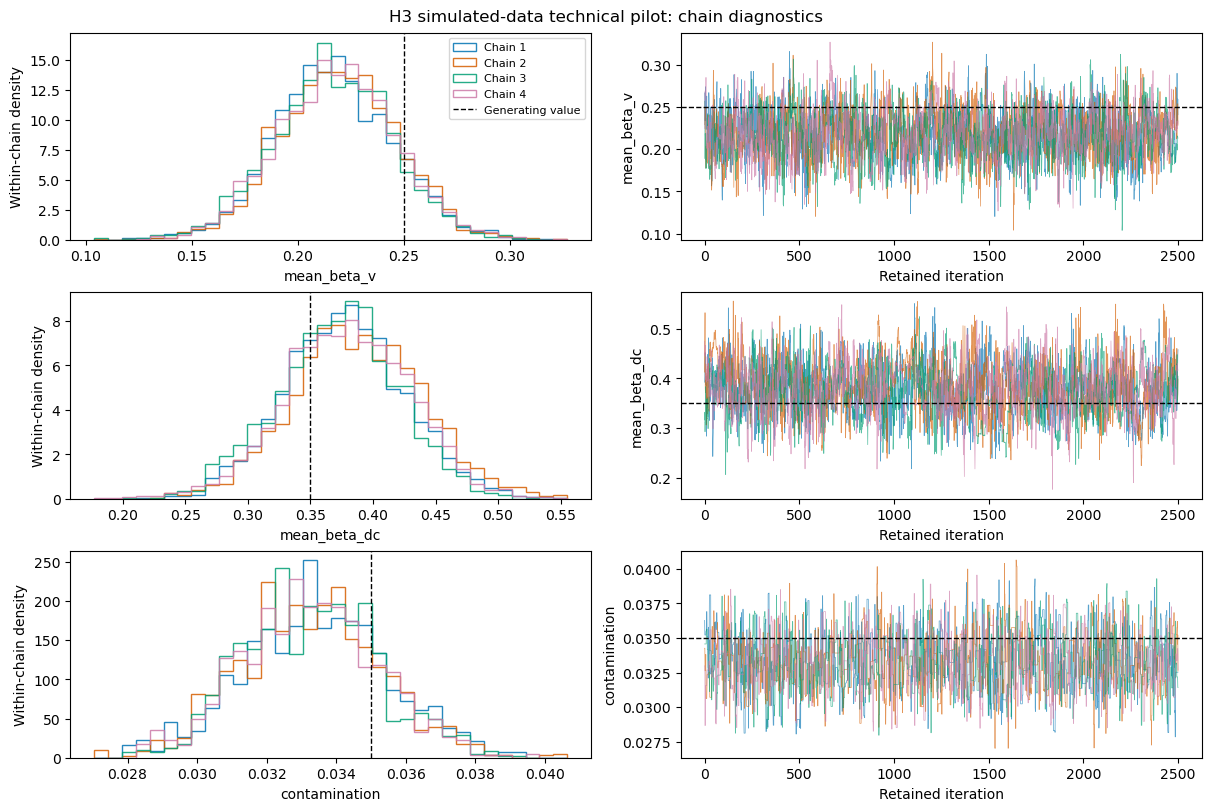

Saved complete simulated-data fit and diagnostics: /repo/02_reanalysis_2026/Output/hddm/matching/mechanism_42_h3_slice_20261024.npz /repo/02_reanalysis_2026/Output/hddm/matching/mechanism_42_h3_diagnostics_20261024.csv


In [6]:

from functools import partial
from multiprocessing import get_context
seeds=[2026102911,2026102921,2026102931,2026102941]
start=time.perf_counter()
worker=partial(run_laplace_chain,model='H3',iterations=4000,burn=1500,global_correction=True,dispersed=True,progress_path='/tmp/matching_progress.log')
with get_context('fork').Pool(4) as pool:chains=pool.map(worker,seeds)
draws=np.stack([x[0] for x in chains])
labels=['mean_'+x for x in names]+['sd_'+x for x in names]+['relation_coef1','relation_coef2','contamination','illegal_rate']+[f'subject_{sub}_{x}' for sub in pilot_subjects for x in names]
truth_flat=np.r_[truth_mu,truth_sd,truth_lcoef,truth_eps,truth_eta,truth_theta.ravel()]
posterior={name:draws[:,:,j] for j,name in enumerate(labels)}
lam=draws[:,:,22:24]@C.T
for i,sub in enumerate(pilot_subjects):
    th=draws[:,:,26+i*11:26+(i+1)*11]
    for cond,x in X.items():
        v=np.exp(th[:,:,3:7]@x);dc=th[:,:,7:11]@x
        posterior[f'derived_{sub}_v_{cond}']=v
        posterior[f'derived_{sub}_dc_{cond}']=dc
        posterior[f'derived_{sub}_mu_match_{cond}']=v+dc
        for r,j in relation_index.items():posterior[f'derived_{sub}_mu_mismatch_{cond}_{r}']=-v*np.exp(lam[:,:,j])+dc
idata=az.from_dict(posterior=posterior)
diagnostics=az.summary(idata,round_to='none',hdi_prob=.95)
print('Elapsed seconds:',time.perf_counter()-start)
print('Individual proposal acceptance range:',min(x[1].min() for x in chains),max(x[1].max() for x in chains))
display(diagnostics.sort_values('r_hat',ascending=False).head(15))
display(diagnostics.loc[['mean_beta_v','mean_beta_dc','sd_beta_v','sd_beta_dc']])
print('All raw and derived parameters:',len(diagnostics),'max Rhat',diagnostics.r_hat.max(),'min bulk',diagnostics.ess_bulk.min(),'min tail',diagnostics.ess_tail.min())
print('Counts failing Rhat/bulk/tail:',int((diagnostics.r_hat>=1.01).sum()),int((diagnostics.ess_bulk<400).sum()),int((diagnostics.ess_tail<400).sum()))
out=ROOT/'Output/hddm/matching/mechanism_42_h3_slice_20261024.npz'
csv=out.with_name('mechanism_42_h3_diagnostics_20261024.csv')
assert not out.exists() and not csv.exists()
np.savez_compressed(out,draws=draws,labels=np.asarray(labels),truth=truth_flat,seeds=np.asarray(seeds),data_seed=2026102901,generated_deadlines=truth_deadlines,subject_ids=np.asarray(pilot_subjects),choices=simulated.choice.to_numpy(),rt=simulated.rt_new.to_numpy(),trial_subject=simulated.Subject.to_numpy(),source_hashes=json.dumps(hashes),acceptance=np.stack([x[1] for x in chains]))
diagnostics.to_csv(csv,index_label='parameter')
plot_pilot_trace(draws,labels,truth_flat);plt.show()
print('Saved complete simulated-data fit and diagnostics:',out,csv)


## 42 人检验：群体与个体参数联合更新

前一轮 42 人试验未通过：最大 R̂=1.10237，最小 bulk ESS=28.45，最小 tail ESS=30.09；1496 个基础及派生量中，117 个 R̂≥1.01、25 个 bulk ESS<400、6 个 tail ESS<400。个体提议接受率正常，但部分层级尺度混合较慢。

保留同一模拟数据、先验及观测模型。针对尺度与个体值的耦合，新增 Gaussian-surrogate 可逆联合转移：随机选择群体均值或尺度更新，在近似模型中积分个体参数后更新所选群体参数，再生成对应个体参数。以原始似然与近似似然的比率进行精确 MH 校正；先验相同，因此在校正中抵消。该步骤不将近似后验作为估计结果。其 Gaussian 基准与数值积分对照中，群体均值和尺度的采样误差分别为 −0.55 和 −0.62 个 MCSE。

四条独立链各 6,000 次，前 2,000 次不保留；使用分散初值。既有结果不覆盖。本轮仍为估计器验收，不以未收敛样本报告模型恢复或真实数据排名。


In [5]:

def slice_scalar(x,target,rng,w=.7):
    height=target(x)+np.log(rng.random());L=x-w*rng.random();R=L+w;J=rng.integers(60);K=59-J
    while J>0 and target(L)>height:L-=w;J-=1
    while K>0 and target(R)>height:R+=w;K-=1
    for _ in range(1000):
        y=rng.uniform(L,R)
        if target(y)>=height:return y
        if y<x:L=y
        else:R=y
    raise RuntimeError('Collapsed slice failed')

def surrogate_hyper_draw(y,h,m,s,pm,ps,sscale,rng,update_mean):
    # Reversible transition under the Gaussian surrogate joint distribution.
    if update_mean:
        V=s*s+1/h
        vm=1/(1/ps**2+np.sum(1/V))
        mm=vm*(pm/ps**2+np.sum(y/V))
        mn=rng.normal(mm,np.sqrt(vm));sn=s
    else:
        def target(logs):
            if abs(logs)>350:return -np.inf
            sig=np.exp(logs);V=sig*sig+1/h
            return logs-.5*sig*sig/sscale**2-.5*np.sum(np.log(V)+(y-m)**2/V)
        sn=np.exp(slice_scalar(np.log(s),target,rng));mn=m
    variance=1/(h+1/sn**2)
    mean=variance*(h*y+mn/sn**2)
    return mn,sn,rng.normal(mean,np.sqrt(variance))

archive42=np.load(ROOT/'Output/hddm/matching/mechanism_42_h3_slice_20261024.npz')
pilot_subjects=archive42['subject_ids'].tolist()
simulated=d.copy().reset_index(drop=True)
assert np.array_equal(simulated.Subject.to_numpy(),archive42['trial_subject'])
simulated['choice']=archive42['choices'];simulated['rt_new']=archive42['rt']
data=prepare(simulated)
truth_flat=archive42['truth'];truth_deadlines=archive42['generated_deadlines']
labels=archive42['labels'].tolist()
center=archive42['draws'].mean(axis=(0,1))
lc_reference=center[22:24];eps_reference=center[24]
proposals=build_proposals(data,allowed('H3'),center[26:].reshape(42,11),lc_reference,eps_reference)
proposal_cross=proposal_cross_curvature(data,allowed('H3'),proposals,lc_reference,eps_reference)
print('Reusing the same 42-person simulated dataset. Priors and likelihood unchanged.')


proposal 1 of 42 evaluations 276 min curvature 12.1924495671527


proposal 2 of 42 evaluations 240 min curvature 12.015815032394881


proposal 3 of 42 evaluations 276 min curvature 13.156584946826404


proposal 4 of 42 evaluations 252 min curvature 12.516402941092196


proposal 5 of 42 evaluations 276 min curvature 10.387270789766445


...

proposal 39 of 42 evaluations 264 min curvature 10.955866778420745


proposal 40 of 42 evaluations 276 min curvature 9.657796214564165


proposal 41 of 42 evaluations 288 min curvature 13.29368077050473


proposal 42 of 42 evaluations 252 min curvature 12.197735047213524


Reusing the same 42-person simulated dataset. Priors and likelihood unchanged.


chain

chain

2026103121

2026103141

iteration

...

6000

Elapsed seconds: 1124.1946084930096
Collapsed hyperparameter acceptance by chain: [[0.758, 0.416, 0.797, 0.199, 0.426, 0.67, 0.643, 0.861, 0.946, 0.938, 0.92], [0.753, 0.387, 0.811, 0.19, 0.424, 0.685, 0.632, 0.841, 0.939, 0.934, 0.914], [0.76, 0.398, 0.824, 0.185, 0.423, 0.69, 0.652, 0.852, 0.955, 0.95, 0.908], [0.777, 0.406, 0.799, 0.179, 0.409, 0.679, 0.636, 0.859, 0.947, 0.941, 0.915]]
Individual proposal acceptance range: 0.43 0.624


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sd_beta_v,0.092176,0.038725,0.000045,0.152739,0.001931,0.001366,418.289795,308.361017,1.010235
sd_v_other,0.058350,0.026354,0.000057,0.100183,0.001592,0.001127,281.135494,334.569347,1.009181
mean_dc_other,-0.071663,0.030098,-0.132352,-0.014336,0.001273,0.000901,558.079344,1093.275328,1.008858
sd_beta_dc,0.150109,0.068924,0.002732,0.264938,0.002389,0.001690,810.946379,623.459430,1.007587
subject_7316_v_other,-0.043473,0.067529,-0.181087,0.069455,0.002711,0.001918,613.436276,1873.090763,1.006810
sd_dc_other,0.039697,0.028878,0.000175,0.094376,0.001006,0.000711,718.846149,808.076784,1.006330
subject_7306_v_other,-0.051931,0.069277,-0.195221,0.059647,0.002760,0.001953,596.984327,1973.105244,1.006048
subject_7316_dc_other,-0.068596,0.051622,-0.171662,0.038063,0.001264,0.000894,1533.968181,2954.113367,1.005720
derived_7323_dc_Good_Self,0.482271,0.128046,0.242759,0.745734,0.002892,0.002045,1918.311851,4235.576858,1.005052
sd_dc_other_contrast,0.104783,0.063884,0.000481,0.217833,0.002113,0.001494,866.606609,920.757285,1.004948


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mean_beta_v,0.217705,0.027230,0.163518,0.269990,0.000574,0.000406,2239.482193,3982.676193,1.001597
mean_beta_dc,0.377869,0.049229,0.283051,0.477129,0.000957,0.000677,2639.208987,4473.059903,1.001416
sd_beta_v,0.092176,0.038725,0.000045,0.152739,0.001931,0.001366,418.289795,308.361017,1.010235
sd_beta_dc,0.150109,0.068924,0.002732,0.264938,0.002389,0.001690,810.946379,623.459430,1.007587


All raw and derived parameters: 1496 max Rhat 1.010235180153046 min bulk 281.1354941401035 min tail 308.3610169363721
Counts failing Rhat/bulk/tail: 1 1 2


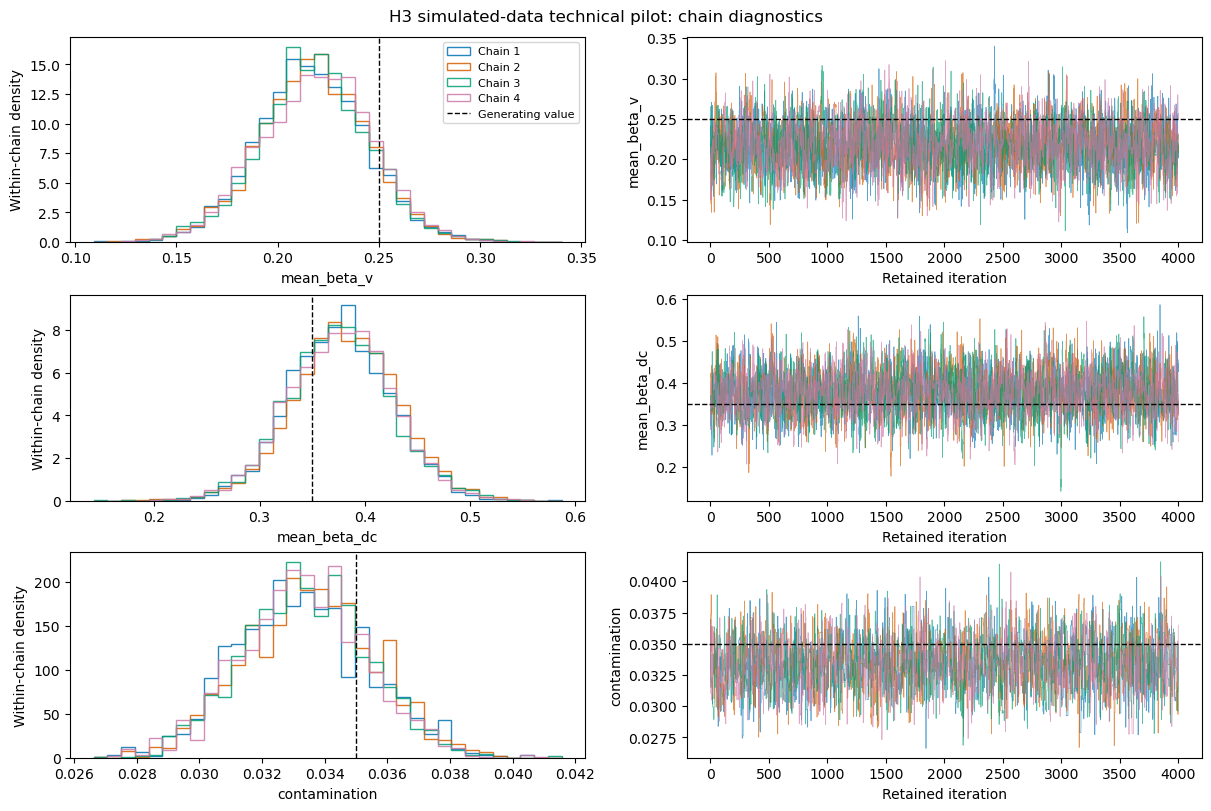

Saved complete simulated-data fit and diagnostics: /repo/02_reanalysis_2026/Output/hddm/matching/mechanism_42_h3_collapsed_20261025.npz /repo/02_reanalysis_2026/Output/hddm/matching/mechanism_42_h3_collapsed_diagnostics_20261025.csv


In [6]:

from functools import partial
from multiprocessing import get_context
seeds=[2026103111,2026103121,2026103131,2026103141]
start=time.perf_counter()
worker=partial(run_laplace_chain,model='H3',iterations=6000,burn=2000,global_correction=True,dispersed=True,progress_path='/tmp/matching_progress.log',collapsed=True)
with get_context('fork').Pool(4) as pool:chains=pool.map(worker,seeds)
draws=np.stack([x[0] for x in chains])
labels=['mean_'+x for x in names]+['sd_'+x for x in names]+['relation_coef1','relation_coef2','contamination','illegal_rate']+[f'subject_{sub}_{x}' for sub in pilot_subjects for x in names]
truth_flat=archive42['truth']
posterior={name:draws[:,:,j] for j,name in enumerate(labels)}
lam=draws[:,:,22:24]@C.T
for i,sub in enumerate(pilot_subjects):
    th=draws[:,:,26+i*11:26+(i+1)*11]
    for cond,x in X.items():
        v=np.exp(th[:,:,3:7]@x);dc=th[:,:,7:11]@x
        posterior[f'derived_{sub}_v_{cond}']=v
        posterior[f'derived_{sub}_dc_{cond}']=dc
        posterior[f'derived_{sub}_mu_match_{cond}']=v+dc
        for r,j in relation_index.items():posterior[f'derived_{sub}_mu_mismatch_{cond}_{r}']=-v*np.exp(lam[:,:,j])+dc
idata=az.from_dict(posterior=posterior)
diagnostics=az.summary(idata,round_to='none',hdi_prob=.95)
print('Elapsed seconds:',time.perf_counter()-start)
print('Collapsed hyperparameter acceptance by chain:',[x[3].round(3).tolist() for x in chains])
print('Individual proposal acceptance range:',min(x[1].min() for x in chains),max(x[1].max() for x in chains))
display(diagnostics.sort_values('r_hat',ascending=False).head(15))
display(diagnostics.loc[['mean_beta_v','mean_beta_dc','sd_beta_v','sd_beta_dc']])
print('All raw and derived parameters:',len(diagnostics),'max Rhat',diagnostics.r_hat.max(),'min bulk',diagnostics.ess_bulk.min(),'min tail',diagnostics.ess_tail.min())
print('Counts failing Rhat/bulk/tail:',int((diagnostics.r_hat>=1.01).sum()),int((diagnostics.ess_bulk<400).sum()),int((diagnostics.ess_tail<400).sum()))
out=ROOT/'Output/hddm/matching/mechanism_42_h3_collapsed_20261025.npz'
csv=out.with_name('mechanism_42_h3_collapsed_diagnostics_20261025.csv')
assert not out.exists() and not csv.exists()
np.savez_compressed(out,draws=draws,labels=np.asarray(labels),truth=truth_flat,seeds=np.asarray(seeds),data_seed=2026102901,generated_deadlines=truth_deadlines,subject_ids=np.asarray(pilot_subjects),choices=simulated.choice.to_numpy(),rt=simulated.rt_new.to_numpy(),trial_subject=simulated.Subject.to_numpy(),source_hashes=json.dumps(hashes),acceptance=np.stack([x[1] for x in chains]))
diagnostics.to_csv(csv,index_label='parameter')
plot_pilot_trace(draws,labels,truth_flat);plt.show()
print('Saved complete simulated-data fit and diagnostics:',out,csv)


## 固定更新规则下的精度续接

联合更新首段结果：1496 个量中仅 1 个 R̂≥1.01、1 个 bulk ESS<400、2 个 tail ESS<400；最大 R̂=1.010235、最小 bulk ESS=281.14、最小 tail ESS=308.36。目标群体 β_v/β_dc 的 R̂=1.00160/1.00142，bulk ESS=2239.48/2639.21。

不再改变模型、先验、提议曲率或更新规则。四链分别从各自末状态继续 4,000 次，不另加预热；初始段已预热 2,000 次，合计每链保留 8,000 次。续接使用独立记录的随机流，与前段按链对应连接，不跨链拼接。旧样本单独保存，新文件记录父样本 SHA256。该操作只增加 Monte Carlo 精度，不增加恢复数据集数量。


chain

2026103221

iteration

1000

chain

...

4000

Elapsed seconds: 755.4416874769959
Collapsed hyperparameter acceptance by chain: [[0.788, 0.4, 0.802, 0.169, 0.419, 0.612, 0.676, 0.832, 0.949, 0.949, 0.902], [0.756, 0.408, 0.801, 0.182, 0.42, 0.651, 0.669, 0.842, 0.952, 0.935, 0.911], [0.768, 0.438, 0.806, 0.199, 0.402, 0.624, 0.662, 0.832, 0.936, 0.951, 0.926], [0.794, 0.45, 0.816, 0.181, 0.472, 0.675, 0.685, 0.835, 0.95, 0.956, 0.92]]
Individual proposal acceptance range: 0.4205 0.627


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sd_v_other,0.058408,0.026307,0.000055,0.100297,0.001091,0.000772,591.250457,573.070125,1.009495
sd_beta_v,0.089987,0.038980,0.000045,0.152153,0.001313,0.000929,890.897317,671.847889,1.005910
subject_7306_v_other,-0.051829,0.068685,-0.189590,0.063456,0.001897,0.001342,1184.359657,3477.164140,1.005513
sd_v_other_contrast,0.083958,0.036359,0.000156,0.142041,0.001100,0.000778,1120.649163,811.647632,1.005047
sd_beta_dc,0.149894,0.069511,0.002873,0.264506,0.001745,0.001234,1571.963103,1236.026152,1.004485
subject_7316_v_other,-0.043441,0.067355,-0.181054,0.069165,0.001864,0.001318,1268.593176,3869.597335,1.004047
sd_dc_other,0.040591,0.029245,0.000053,0.095630,0.000738,0.000522,1357.023289,1480.044599,1.004036
mean_dc_other,-0.072064,0.030343,-0.132897,-0.014839,0.000877,0.000620,1198.306965,2417.239490,1.003840
subject_7320_v_other,-0.041330,0.065281,-0.178624,0.064596,0.001636,0.001157,1528.616299,5715.084290,1.003459
subject_7319_v_other,-0.028278,0.062041,-0.160616,0.077773,0.001403,0.000992,1925.927145,5856.011327,1.003458


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mean_beta_v,0.217081,0.027406,0.163264,0.270137,0.000428,0.000303,4080.063654,8050.091124,1.001201
mean_beta_dc,0.378155,0.049521,0.282071,0.476538,0.000700,0.000496,4997.540606,8780.729095,1.000965
sd_beta_v,0.089987,0.038980,0.000045,0.152153,0.001313,0.000929,890.897317,671.847889,1.005910
sd_beta_dc,0.149894,0.069511,0.002873,0.264506,0.001745,0.001234,1571.963103,1236.026152,1.004485


All raw and derived parameters: 1496 max Rhat 1.0094948598052538 min bulk 591.2504571592879 min tail 573.0701245412503
Counts failing Rhat/bulk/tail: 0 0 0


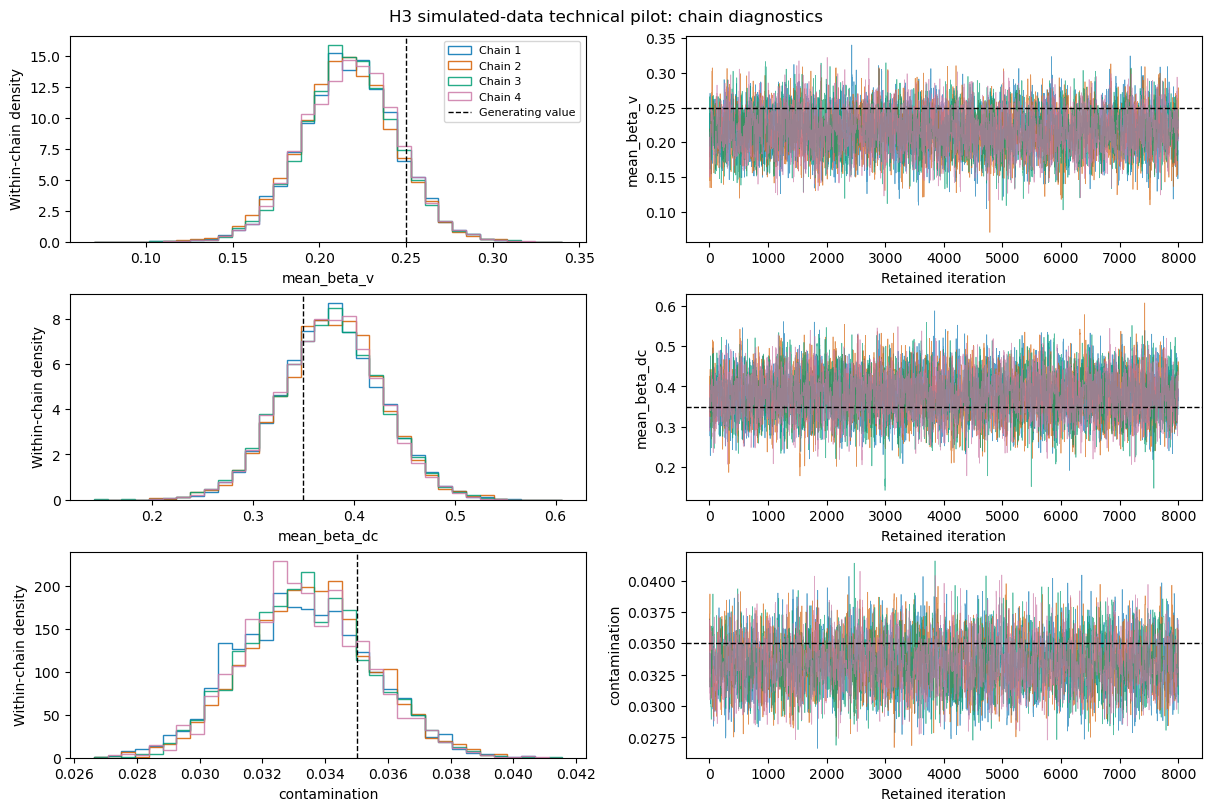

Saved complete simulated-data fit and diagnostics: /repo/02_reanalysis_2026/Output/hddm/matching/mechanism_42_h3_extended_20261025.npz /repo/02_reanalysis_2026/Output/hddm/matching/mechanism_42_h3_extended_diagnostics_20261025.csv


In [6]:

from functools import partial
from multiprocessing import get_context
extension_seeds=[2026103211,2026103221,2026103231,2026103241]
previous_complete=np.load(ROOT/'Output/hddm/matching/mechanism_42_h3_collapsed_20261025.npz')
seeds=previous_complete['seeds']
def extend_one(job):
    seed,state=job
    return run_laplace_chain(seed,model='H3',iterations=4000,burn=0,global_correction=True,dispersed=False,progress_path='/tmp/matching_progress.log',collapsed=True,initial_state=state)
start=time.perf_counter()
with get_context('fork').Pool(4) as pool:chains=pool.map(extend_one,list(zip(extension_seeds,previous_complete['draws'][:,-1,:])))
new_draws=np.stack([x[0] for x in chains])
draws=np.concatenate([previous_complete['draws'],new_draws],axis=1)
labels=['mean_'+x for x in names]+['sd_'+x for x in names]+['relation_coef1','relation_coef2','contamination','illegal_rate']+[f'subject_{sub}_{x}' for sub in pilot_subjects for x in names]
truth_flat=archive42['truth']
posterior={name:draws[:,:,j] for j,name in enumerate(labels)}
lam=draws[:,:,22:24]@C.T
for i,sub in enumerate(pilot_subjects):
    th=draws[:,:,26+i*11:26+(i+1)*11]
    for cond,x in X.items():
        v=np.exp(th[:,:,3:7]@x);dc=th[:,:,7:11]@x
        posterior[f'derived_{sub}_v_{cond}']=v
        posterior[f'derived_{sub}_dc_{cond}']=dc
        posterior[f'derived_{sub}_mu_match_{cond}']=v+dc
        for r,j in relation_index.items():posterior[f'derived_{sub}_mu_mismatch_{cond}_{r}']=-v*np.exp(lam[:,:,j])+dc
idata=az.from_dict(posterior=posterior)
diagnostics=az.summary(idata,round_to='none',hdi_prob=.95)
print('Elapsed seconds:',time.perf_counter()-start)
print('Collapsed hyperparameter acceptance by chain:',[x[3].round(3).tolist() for x in chains])
print('Individual proposal acceptance range:',min(x[1].min() for x in chains),max(x[1].max() for x in chains))
display(diagnostics.sort_values('r_hat',ascending=False).head(15))
display(diagnostics.loc[['mean_beta_v','mean_beta_dc','sd_beta_v','sd_beta_dc']])
print('All raw and derived parameters:',len(diagnostics),'max Rhat',diagnostics.r_hat.max(),'min bulk',diagnostics.ess_bulk.min(),'min tail',diagnostics.ess_tail.min())
print('Counts failing Rhat/bulk/tail:',int((diagnostics.r_hat>=1.01).sum()),int((diagnostics.ess_bulk<400).sum()),int((diagnostics.ess_tail<400).sum()))
out=ROOT/'Output/hddm/matching/mechanism_42_h3_extended_20261025.npz'
csv=out.with_name('mechanism_42_h3_extended_diagnostics_20261025.csv')
assert not out.exists() and not csv.exists()
np.savez_compressed(out,draws=draws,labels=np.asarray(labels),truth=truth_flat,seeds=np.asarray(seeds),extension_seeds=np.asarray(extension_seeds),parent_sha256=hashlib.sha256((ROOT/'Output/hddm/matching/mechanism_42_h3_collapsed_20261025.npz').read_bytes()).hexdigest(),data_seed=2026102901,generated_deadlines=truth_deadlines,subject_ids=np.asarray(pilot_subjects),choices=simulated.choice.to_numpy(),rt=simulated.rt_new.to_numpy(),trial_subject=simulated.Subject.to_numpy(),source_hashes=json.dumps(hashes),acceptance=np.stack([x[1] for x in chains]))
diagnostics.to_csv(csv,index_label='parameter')
plot_pilot_trace(draws,labels,truth_flat);plt.show()
print('Saved complete simulated-data fit and diagnostics:',out,csv)


## 独立 42 人恢复批次

H0–H3 各两个独立数据集，全部保留原始 42×600 刺激安排；生成响应、污染、非法事件及共同截止值均由记录的独立种子控制。非零生成效应 β_log(v)=0.25、β_dc=0.35，其他参数及零和 log 关系难度沿用上文。零效应模型同时固定对应个体效应和随机方差为零。此设计的恢复结论仅适用于这些生成参数及假设。

每个拟合先用 2,000 次迭代校准提议，再冻结提议、执行 10,000 次，其中前 2,000 次不保留。四链全部重要参数接受同一诊断标准；若精度不足，最多续接 8,000 次，规则和先验不变。仍未通过则停止批次并保留失败结果，不输出模型排名。每次只并行四条链，模型之间顺序运行。

模型预测比较使用整合共享截止后的条件留一试次密度 L(y)/L(y_-i)，不是把相关试次强行分解为独立似然。预测目标是已有被试的新试次。优化后的条件计算与直接实现对全部 25,200 个事件一致，最大差 2.84×10⁻¹⁴；原实现另通过联合似然删一比值检查。H0–H3 紧凑参数路由各完成一次有限更新检查。这些是计算验证，不是恢复结果。

PSIS 诊断超限的比较不排名。通过诊断的数据集记录最高预测得分模型及与次高模型的差异，以被试聚类估算差异标准误；差异不超过两倍标准误时标记 ambiguous。恢复计数同时保留此不确定性标签，不能把计数表等同于确定机制判断。没有有效比较的行保留缺失值。每行仅两个数据集不构成充分恢复验证。

模拟中的截止代理是给定的生成输入。真实记录的代理来自无反应试次，未来真实数据留一预测须处理这一来源；不能直接把本批次条件预测当作无信息泄漏的真实交叉验证。

参数恢复表仅汇总生成模型自身拟合的自由参数：记录估计误差、95% 等尾区间、是否覆盖及后验标准差。单份数据的误差不是重复抽样偏差，单次覆盖不是覆盖率。H3 另记录两个群体效应的后验相关。所有候选模型的完整抽样和诊断均保存。

### 首批恢复进度：已完成 18/32 个拟合时的记录

已完成拟合的全部基础与派生检查量均通过当前标准：跨拟合最大 R̂=1.009565，最小 bulk ESS=699.46、最小 tail ESS=533.51。H0 与 H1 各两份数据的四模型比较已完成；H2 第一份数据正在拟合，H3 生成数据尚未比较。本段是阶段性记录，实时进度以末尾执行状态为准。

| 生成数据 | 预测得分最高模型 | 与次高模型的得分差 | 被试聚类标准误 | 判断 |
|---|---|---:|---:|---|
| H0，第 1 份 | H2（次高 H0） | 1.34 | 2.89 | 无明确胜者 |
| H0，第 2 份 | H0（次高 H1） | 1.09 | 1.95 | 无明确胜者 |
| H1，第 1 份 | H1（次高 H3） | 0.30 | 1.20 | 无明确胜者 |
| H1，第 2 份 | H1（次高 H3） | 0.77 | 1.17 | 无明确胜者 |

在两份 H1 数据中，H1 相对 H2 的预测得分差分别为 64.27（SE=13.67）和 51.96（SE=12.53）。因此，在本批固定生成效应下，v 机制与纯 dc 机制呈现可区分的预测，但仍不能凭此排除容纳 v 效应的 H3。四份完整比较的最大 Pareto-k 均小于各自阈值，最大为 0.635。

H1 自身拟合的群体 β_log(v) 后验均值分别为 0.2408、0.2226，95% 等尾区间为 [0.1869,0.2935]、[0.1709,0.2727]，两者均包含生成值 0.25。这是两个数据集的恢复记录，不构成精确覆盖率估计。当前无真实响应拟合或真实机制排名。

### 批次完成核查（2026-10-26）

32/32 个拟合与条件预测计算已保存，全部采样诊断通过：最大 R̂=1.009565，最小 bulk/tail ESS=683.44/533.51。H3 第 1 份数据中 H3 优于次高 H1（预测得分差 29.63，被试聚类 SE=8.02）。H3 第 2 份数据的 H1 拟合有一个试次 Pareto-k=0.72742，超过本次阈值 0.67644，因此该份数据不排名，须局部修正或直接留一重拟合后复核。每类仅两个重复，仍是初步恢复检验。

批次末尾 Notebook 回写因临时驱动器的路径变量被数据 Series 覆盖而失败；已从保存的 execution_status.json 补回状态输出，没有重跑采样或修改统计文件。容器退出码 1 对应这一回写错误，不代表已保存的 32 个拟合失败。


In [ ]:
# Frozen first recovery batch: two independent datasets per generating model.
from multiprocessing import get_context
from functools import partial
import traceback

RECOVERY_DIR=ROOT/'Output/hddm/matching/mechanism_recovery_20261025'

def recovery_labels(model):
    active=allowed(model)
    return (['mean_'+names[j] for j in active]+['sd_'+names[j] for j in active]+
            ['relation_coef1','relation_coef2','contamination','illegal_rate']+
            [f'subject_{s}_{names[j]}' for s in subjects for j in active])

def recovery_diagnostics(draws,model):
    active=allowed(model);k=len(active);labels=recovery_labels(model)
    posterior={name:draws[:,:,j] for j,name in enumerate(labels)}
    lam=draws[:,:,2*k:2*k+2]@C.T
    for i,sub in enumerate(subjects):
        th=np.zeros((*draws.shape[:2],11));th[:,:,active]=draws[:,:,2*k+4+i*k:2*k+4+(i+1)*k]
        for cond,x in X.items():
            v=np.exp(th[:,:,3:7]@x);dc=th[:,:,7:11]@x
            posterior[f'derived_{sub}_v_{cond}']=v
            posterior[f'derived_{sub}_dc_{cond}']=dc
            posterior[f'derived_{sub}_mu_match_{cond}']=v+dc
            for r,j in relation_index.items():
                posterior[f'derived_{sub}_mu_mismatch_{cond}_{r}']=-v*np.exp(lam[:,:,j])+dc
    return az.summary(az.from_dict(posterior=posterior),round_to='none',hdi_prob=.95)

def recovery_gate(table):
    cols=table[['r_hat','ess_bulk','ess_tail']]
    return bool(np.isfinite(cols.to_numpy()).all() and (cols.r_hat<1.01).all() and
                (cols.ess_bulk>=400).all() and (cols.ess_tail>=400).all())

def recovery_generate():
    RECOVERY_DIR.mkdir(exist_ok=True)
    created=[]
    for gi,generator in enumerate(MODELS):
        for rep in [1,2]:
            seed=2026110100+gi*10+rep
            path=RECOVERY_DIR/f'{generator}_r{rep:02d}_data.npz'
            if path.exists():
                saved=np.load(path);assert int(saved['seed'])==seed
                assert json.loads(str(saved['source_hashes']))==hashes
                created.append(path);continue
            rng=np.random.default_rng(seed)
            m=np.array([np.log(1.1),np.log(.25),logit(.56),np.log(1.8),.05,.05,.25,0,0,.1,.35])
            sd=np.array([.08,.08,.12,.15,.08,.08,.10,.12,.08,.08,.12])
            inactive=list(set(range(11))-set(allowed(generator)))
            m[inactive]=0;sd[inactive]=0
            theta=rng.normal(m,sd,size=(42,11))
            lam=np.array([-.10,-.03,.13])
            frame,Ds=simulate(d.copy().reset_index(drop=True),theta,lam,.035,.001,rng)
            np.savez_compressed(path,choices=frame.choice.to_numpy(),rt=frame.rt_new.to_numpy(),
                trial_subject=frame.Subject.to_numpy(),subject_ids=np.asarray(subjects),seed=seed,
                generator=generator,truth_mu=m,truth_sd=sd,truth_theta=theta,truth_lam=lam,
                truth_eps=.035,truth_eta=.001,generated_deadlines=Ds,source_hashes=json.dumps(hashes))
            created.append(path)
    return created

def recovery_chain_job(job):
    seed,model,iterations,burn,state,log=job
    return run_laplace_chain(seed,model=model,iterations=iterations,burn=burn,
        global_correction=True,dispersed=state is None,collapsed=True,
        initial_state=state,progress_path=str(log))

def recovery_chain_batch(model,seeds,iterations,burn,states,log):
    jobs=[(int(seed),model,iterations,burn,state,log) for seed,state in zip(seeds,states)]
    with get_context('fork').Pool(4) as pool:return pool.map(recovery_chain_job,jobs)

def recovery_fit(dataset,model,fit_id):
    global data,proposals,proposal_cross,lc_reference,eps_reference
    saved=np.load(dataset);frame=d.copy().reset_index(drop=True)
    assert np.array_equal(frame.Subject,saved['trial_subject'])
    frame['choice']=saved['choices'];frame['rt_new']=saved['rt']
    data=prepare(frame);active=allowed(model);k=len(active)
    stem=RECOVERY_DIR/(dataset.stem.replace('_data','')+'_'+model)
    target=stem.with_name(stem.name+'_fit.npz');summary=stem.with_name(stem.name+'_diagnostics.csv')
    if target.exists():
        table=pd.read_csv(summary,index_col=0)
        if not recovery_gate(table):raise RuntimeError('Existing fit failed diagnostics: '+str(target))
        return target,frame
    lc_reference=np.zeros(2);eps_reference=.05
    proposals=build_proposals(data,active,np.tile(prior_mu,(42,1)),lc_reference,eps_reference)
    proposal_cross=proposal_cross_curvature(data,active,proposals,lc_reference,eps_reference)
    seeds=np.arange(4)+2026120000+fit_id*100
    log=stem.with_name(stem.name+'_progress.log')
    warm_path=stem.with_name(stem.name+'_warmup.npz')
    if warm_path.exists():
        warm=np.load(warm_path)['draws']
    else:
        warm_chains=recovery_chain_batch(model,seeds,2000,1000,[None]*4,log)
        warm=np.stack([x[0] for x in warm_chains])
        np.savez_compressed(warm_path,draws=warm,seeds=seeds,labels=recovery_labels(model),
                            status='proposal_calibration_only_not_posterior_result')
    center=warm.mean(axis=(0,1));starts=np.zeros((42,11))
    starts[:,active]=center[2*k+4:].reshape(42,k)
    lc_reference=center[2*k:2*k+2];eps_reference=center[2*k+2]
    proposals=build_proposals(data,active,starts,lc_reference,eps_reference)
    proposal_cross=proposal_cross_curvature(data,active,proposals,lc_reference,eps_reference)
    production=recovery_chain_batch(model,seeds+10,10000,2000,list(warm[:,-1,:]),log)
    draws=np.stack([x[0] for x in production]);table=recovery_diagnostics(draws,model)
    stage=stem.with_name(stem.name+'_segment1.npz')
    if stage.exists():raise FileExistsError(stage)
    np.savez_compressed(stage,draws=draws,seeds=seeds+10,labels=recovery_labels(model),
                        acceptance=np.stack([x[1] for x in production]))
    extended=False
    if not recovery_gate(table):
        table.to_csv(stem.with_name(stem.name+'_segment1_diagnostics.csv'))
        # One bounded precision extension. No changes to likelihood, priors or proposals.
        extra=recovery_chain_batch(model,seeds+20,8000,0,list(draws[:,-1,:]),log)
        draws=np.concatenate([draws,np.stack([x[0] for x in extra])],axis=1)
        table=recovery_diagnostics(draws,model);extended=True
    table.to_csv(summary,index_label='parameter')
    np.savez_compressed(target,draws=draws,labels=recovery_labels(model),model=model,
                        seeds=seeds+10,extension_seeds=seeds+20 if extended else [],
                        data_sha256=hashlib.sha256(dataset.read_bytes()).hexdigest(),
                        source_hashes=json.dumps(hashes),diagnostics_pass=recovery_gate(table))
    if not recovery_gate(table):
        raise RuntimeError(f'{target.name}: sampler failed after bounded extension; no ranking permitted')
    return target,frame

# The deadline is integrated jointly within subject. These are conditional
# leave-one-trial densities, NOT a factorization of the joint likelihood.
def recovery_loo_context(frame):
    context=[]
    for sub,ss in frame.groupby('Subject',sort=True):
        good=ss.choice.ge(0);rr=np.sort(ss.loc[good,'rt_new'].to_numpy())
        mx=rr[-1] if len(rr) else -np.inf
        maxima=ss.index[good & ss.rt_new.eq(mx)].to_numpy()
        groups=[]
        for key,g in ss.groupby(['condition','stim','relation'],sort=True):
            seen=g.choice.ge(0)
            groups.append((key,g.index[seen].to_numpy(),g.loc[seen,'rt_new'].to_numpy(),
                g.loc[seen,'choice'].to_numpy(),g.index[g.choice.eq(-1)].to_numpy(),
                g.index[g.choice.eq(-2)].to_numpy()))
        context.append((float(deadlines[sub]),mx,rr[-2] if len(rr)>1 else -np.inf,
                        int(maxima[0]) if len(maxima)==1 else None,groups))
    return context

def recovery_conditional_loglik(context,theta,lam,eps,eta):
    vals=np.full(25200,np.nan)
    gx,gw=quadrature_nodes(7)
    for i,(proxy,mx,second,max_idx,groups) in enumerate(context):
        L=proxy-.001;U=proxy+.001;lo=max(L,mx)
        ds=lo+(gx+1)*(U-lo)/2
        logw=np.log(gw/2)+np.log((U-lo)/(U-L))
        pars=[unpack(theta[i],*g[0],lam) for g in groups]
        survival_logs=np.array([np.log(mix_survival(ds,a,t,z,mu,eps)) for a,t,z,mu in pars])
        counts=np.array([len(g[4]) for g in groups]);base=logw+counts@survival_logs
        full=logsumexp(base)
        for j,((_,idx,rt,resp,time_idx,bad_idx),(a,t,z,mu)) in enumerate(zip(groups,pars)):
            vals[idx]=np.log1p(-eta)+np.log(mix_density(rt,resp,a,t,z,mu,eps))
            vals[time_idx]=np.log1p(-eta)+full-logsumexp(base-survival_logs[j])
            vals[bad_idx]=np.log(eta)
        if max_idx is not None and mx>L:
            lo2=max(L,second);ds2=lo2+(gx+1)*(U-lo2)/2
            lw2=np.log(gw/2)+np.log((U-lo2)/(U-L))
            for nt,(a,t,z,mu) in zip(counts,pars):
                if nt:lw2+=nt*np.log(mix_survival(ds2,a,t,z,mu,eps))
            vals[max_idx]+=full-logsumexp(lw2)
    if not np.isfinite(vals).all():raise ArithmeticError('Nonfinite conditional predictive density')
    return vals

def recovery_score(fit_path,frame):
    output=fit_path.with_name(fit_path.stem.replace('_fit','')+'_loo.csv')
    if output.exists():return pd.read_csv(output)
    saved=np.load(fit_path);model=str(saved['model']);active=allowed(model);k=len(active)
    draws=saved['draws'];step=max(1,draws.shape[1]//300);selected=draws[:,::step,:]
    context=recovery_loo_context(frame)
    likelihood=np.empty((*selected.shape[:2],len(frame)))
    for ch in range(4):
        for it,row in enumerate(selected[ch]):
            theta=np.zeros((42,11));theta[:,active]=row[2*k+4:].reshape(42,k)
            likelihood[ch,it]=recovery_conditional_loglik(context,theta,C@row[2*k:2*k+2],row[2*k+2],row[2*k+3])
        print('conditional predictive chain',ch+1,model,flush=True)
    idata=az.from_dict(posterior={'contamination':selected[:,:,2*k+2]},
                       log_likelihood={'event':likelihood})
    # Conservative reff uses the minimum ESS among stored important raw parameters.
    diag=pd.read_csv(fit_path.with_name(fit_path.stem.replace('_fit','')+'_diagnostics.csv'),index_col=0)
    reff=min(1.,float(diag.ess_bulk.min())/(4*draws.shape[1]))
    result=az.loo(idata,var_name='event',pointwise=True,reff=reff)
    table=pd.DataFrame({'Subject':frame.Subject,'elpd_loo':result.loo_i.values,
                        'pareto_k':result.pareto_k.values,
                        'pareto_threshold':min(.7,1-1/np.log10(selected.shape[0]*selected.shape[1]))})
    table.to_csv(output,index=False)
    return table

def recovery_summarize():
    estimates=[];comparisons=[];matrix=pd.DataFrame(0,index=MODELS,columns=MODELS)
    for dataset in sorted(RECOVERY_DIR.glob('*_data.npz')):
        saved=np.load(dataset);generator=str(saved['generator']);prefix=dataset.stem.replace('_data','')
        truefit=RECOVERY_DIR/(prefix+'_'+generator+'_fit.npz')
        if truefit.exists():
            fit=np.load(truefit)
            if bool(fit['diagnostics_pass']):
                active=allowed(generator);k=len(active);dr=fit['draws'].reshape(-1,fit['draws'].shape[-1])
                truth=np.r_[saved['truth_mu'][active],saved['truth_sd'][active],C.T@saved['truth_lam'],saved['truth_eps'],saved['truth_eta']]
                labels=recovery_labels(generator)
                corr=float(np.corrcoef(dr[:,labels.index('mean_beta_v')],dr[:,labels.index('mean_beta_dc')])[0,1]) if generator=='H3' else np.nan
                for j,value in enumerate(truth):
                    lo,hi=np.quantile(dr[:,j],[.025,.975])
                    estimates.append(dict(dataset=prefix,generator=generator,parameter=labels[j],truth=value,
                        mean=dr[:,j].mean(),error=dr[:,j].mean()-value,lower=lo,upper=hi,
                        covered=bool(lo<=value<=hi),posterior_sd=dr[:,j].std(ddof=1),beta_v_dc_posterior_correlation=corr))
        scores={m:RECOVERY_DIR/(prefix+'_'+m+'_loo.csv') for m in MODELS}
        if not all(p.exists() for p in scores.values()):continue
        tables={m:pd.read_csv(p) for m,p in scores.items()}
        maxk=max(t.pareto_k.max() for t in tables.values())
        threshold=min(float(t.pareto_threshold.iloc[0]) for t in tables.values())
        if not np.isfinite(maxk) or maxk>threshold:
            comparisons.append(dict(dataset=prefix,generator=generator,status='psis_unreliable',winner=None,max_pareto_k=maxk));continue
        total={m:t.elpd_loo.sum() for m,t in tables.items()};order=sorted(total,key=total.get,reverse=True)
        win,second=order[:2];difference=tables[win].elpd_loo-tables[second].elpd_loo
        cluster=difference.groupby(tables[win].Subject).sum()
        se=float(np.sqrt(len(cluster)*cluster.var(ddof=1)))
        gap=float(difference.sum());matrix.loc[generator,win]+=1
        comparisons.append(dict(dataset=prefix,generator=generator,status='decisive' if gap>2*se else 'ambiguous',
            winner=win,runner_up=second,elpd_difference=gap,subject_cluster_SE=se,max_pareto_k=maxk))
    pd.DataFrame(estimates).to_csv(RECOVERY_DIR/'parameter_recovery.csv',index=False)
    pd.DataFrame(comparisons).to_csv(RECOVERY_DIR/'model_comparisons.csv',index=False)
    # Missing rows are not zero recoveries. Counts include ambiguous maxima; see comparisons.
    for g in MODELS:
        if not any(c['generator']==g and c['status']!='psis_unreliable' for c in comparisons):matrix.loc[g,:]=np.nan
    matrix.to_csv(RECOVERY_DIR/'model_recovery_counts.csv',index_label='generating_model')
    return estimates,comparisons

def run_recovery_batch():
    RECOVERY_DIR.mkdir(exist_ok=True)
    status_path=RECOVERY_DIR/'execution_status.json'
    if status_path.exists():raise FileExistsError('Batch already exists; inspect saved state before resuming')
    spec=dict(status='generating',replicates_per_model=2,subjects=42,trials_per_subject=600,
        zero_sum_log_relation=True,deadline_halfwidth=.001,nominal_effects={'beta_v':.25,'beta_dc':.35},
        calibration_dataset_excluded=True,source_hashes=hashes,
        scope='initial recovery pilot; not a precise error-rate or coverage study',
        notebook_sha256=hashlib.sha256((ROOT/'matching_observation_recovery.ipynb').read_bytes()).hexdigest(),
        python=platform.python_version(),hddm=hddm.__version__,numpy=np.__version__,arviz=az.__version__,completed=[])
    def save():status_path.write_text(json.dumps(spec,indent=2),encoding='utf-8')
    save()
    try:
        datasets=recovery_generate()
        for di,dataset in enumerate(datasets):
            for mi,model in enumerate(MODELS):
                spec.update(status='fitting',dataset=dataset.name,model=model);save()
                fit,frame=recovery_fit(dataset,model,di*4+mi)
                spec['status']='conditional_predictive_check';save()
                recovery_score(fit,frame)
                spec['completed'].append({'dataset':dataset.name,'model':model,'fit':fit.name})
                recovery_summarize();save()
        spec['status']='initial_recovery_batch_complete';save()
    except Exception:
        spec.update(status='failed',error=traceback.format_exc());save()
        raise
    return spec


In [ ]:
# Explicit long-running entry; inspect execution_status.json before starting.
RUN_RECOVERY_BATCH = False
if RUN_RECOVERY_BATCH:
    batch_result = run_recovery_batch()
    display(batch_result)
else:
    status_path=RECOVERY_DIR/'execution_status.json'
    display(json.loads(status_path.read_text()) if status_path.exists() else {'status':'not_started'})


{
  "status": "initial_recovery_batch_complete",
  "replicates_per_model": 2,
  "subjects": 42,
  "trials_per_subject": 600,
  "zero_sum_log_relation": true,
  "deadline_halfwidth": 0.001,
  "nominal_effects": {
    "beta_v": 0.25,
    "beta_dc": 0.35
  },
  "calibration_dataset_excluded": true,
  "source_hashes": {
    "raw": "ee0da77b217f5f4719e41efa7adae207b1f1deacd87ee86acb1bd50ff528afbc",
    "subjects": "2ad1d92d3828f474efd78956068320d49705b9a2bc84f51a5823cec20042e1d8",
    "parameters": "81e468b380e44af75809fbc901c24a818ed7c929b4bf23ce72e1707a48e5796a",
    "diagnostics": "af5a5eed9f17cb5a4bbdcf8ecfd4a032266d879209e0622d8f1e4c23f0541025"
  },
  "scope": "initial recovery pilot; not a precise error-rate or coverage study",
  "notebook_sha256": "dcbb5caafb299a91b4d1118d59eea30d4bb208ac195de2a382449587370e8677",
  "python": "3.9.13",
  "hddm": "1.0.1RC",
  "numpy": "1.23.3",
  "arviz": "0.15.1",
  "completed": [
    {
      "dataset": "H0_r01_data.npz",
      "model": "H0",
      "

## 真实 Matching 数据入口：已准备，未拟合

真实拟合只使用原始 Matching 响应，不把模拟数据、模拟参数后验或恢复估计当成真实数据或经验先验。沿用同一模型定义、先验、零和关系难度参照及观测似然。恢复分析用于判断能否开展可靠推断；它不是拟合输入。

数据准备保留 42 人的全部 25,200 个试次：24,527 条合法响应、649 条超时、24 条非法按键。按被试各自的 m/n 映射编码 Match 上边界，合法响应逐行与已有输入表核对；source_row 使用含表头的一基 CSV 物理行号。RT、选择、刺激和被试编号均核对通过。原始数据不修改。

`run_real_matching(execute=False)` 仅返回数据核查及执行信息，不创建输出目录。正式执行仍须恢复批次完成、研究者根据恢复结果作出有依据的科学判断；完成 32 个拟合本身不自动意味着模型可识别。真实拟合和 PPC 代码尚未实际运行，不能据此宣称真实模型通过验证。

未来拟合将复用现有估计器，在独立进程中顺序拟合四模型，每模型四链，使用新随机种子和独立输出目录。保留全部参数诊断、样本及运行状态；已有结果目录不覆盖。当前恢复容器的代码和调度未修改。

PPC 已实现从各链抽取 50 个后验样本，模拟相同被试和试次安排。共享截止按给定参数及该被试观测数据的条件后验抽取，采用与积分一致的七点求积近似；不把截止代理当成精确已知值。报告选择、正确率、正确/错误 RT 均值与分位数、超时和非法事件，并计算被试内 Good-self−Bad-self 差异。快速反应使用观测 Self 响应按刺激类型合并后的第 20 百分位作为固定阈值，各重复保持不变；报告有成对数据的被试数，避免掩盖空单元。此为样本内 PPC，不是交叉验证。

真实数据的预测比较仍待处理截止代理的信息来源，代码不会自动沿用模拟数据的 PSIS 排名。目前完成 Python 语法、真实编码、四模型后验解码、条件截止支持范围及禁止提前启动的检查；未执行真实 MCMC、完整真实 PPC 或样本外预测比较。


In [ ]:
# Real-data entry uses observed events only; simulated responses are never inputs.
def prepare_real_matching():
    frame=raw.loc[raw.Subject.isin(subjects)].copy()
    frame['source_row']=frame.index+2  # Physical CSV line: one-based, header included
    frame=frame.reset_index(drop=True)
    assert np.array_equal(frame.Subject.to_numpy(),d.Subject.to_numpy())
    for col in ['condition','stim','relation']:frame[col]=d[col].to_numpy()
    keys=frame.groupby(['Subject','Match']).CorrResp.agg(lambda x:tuple(pd.unique(x)))
    assert keys.map(len).eq(1).all()
    upper={sub:keys.loc[(sub,'match')][0] for sub in subjects}
    lower={sub:keys.loc[(sub,'mismatch')][0] for sub in subjects}
    assert all({upper[sub],lower[sub]}=={'m','n'} for sub in subjects)
    valid=frame.Resp.eq(frame.Subject.map(upper)) | frame.Resp.eq(frame.Subject.map(lower))
    timeout=frame.ACC.eq(-1)
    assert (frame.loc[timeout,'Resp']=='NA').all() and not (valid & timeout).any()
    frame['choice']=-2
    frame.loc[timeout,'choice']=-1
    frame.loc[valid,'choice']=frame.loc[valid,'Resp'].eq(frame.loc[valid,'Subject'].map(upper)).astype(int)
    frame['rt_new']=np.where(valid,pd.to_numeric(frame.RT),np.nan)
    assert (frame.loc[valid,'rt_new']>0).all()
    assert np.array_equal((frame.loc[valid,'choice']==frame.loc[valid,'stim']).astype(int),frame.loc[valid,'ACC'])
    previous=pd.read_csv(ROOT/'Data/matching_input.csv').set_index('source_row').sort_index()
    actual=frame.loc[valid].set_index('source_row').sort_index()
    assert actual.index.equals(previous.index)
    assert np.array_equal(actual.choice,previous.response)
    assert np.array_equal(actual.stim,previous.stim)
    assert np.array_equal(actual.Subject,previous.subj_idx)
    assert np.allclose(actual.rt_new,previous.rt,rtol=0,atol=1e-12)
    counts={'legal':int(valid.sum()),'timeout':int(timeout.sum()),'illegal':int((~valid & ~timeout).sum())}
    assert counts=={'legal':24527,'timeout':649,'illegal':24}
    for item in prepare(frame):
        assert item['maxrt']<item['proxy']+.001, 'Observed RT incompatible with deadline working support'
    return frame,dict(subjects=42,trials=len(frame),events=counts,
        source_hashes={k:hashlib.sha256(p.read_bytes()).hexdigest() for k,p in paths.items()},
        legacy_input_sha256=hashlib.sha256((ROOT/'Data/matching_input.csv').read_bytes()).hexdigest(),
        difficulty_reference='sum(log relation multipliers)=0',
        deadline_model='one D per subject; Uniform(record-derived proxy +/- .001 s)',
        choice_coding='upper boundary Match; participant-specific m/n mapping',
        legacy_legal_rows_verified=True)

def real_fit_parameters(row,model):
    active=allowed(model);k=len(active)
    assert len(row)==2*k+4+42*k
    theta=np.zeros((42,11));theta[:,active]=row[2*k+4:].reshape(42,k)
    return theta,C@row[2*k:2*k+2],float(row[2*k+2]),float(row[2*k+3])

def real_posterior_deadlines(frame,theta,lam,eps,rng):
    # Discrete quadrature approximation to p(D_i | all observed events, parameters).
    gx,gw=quadrature_nodes(7);out=[]
    for th,item in zip(theta,prepare(frame)):
        lower=max(item['proxy']-.001,item['maxrt']);upper=item['proxy']+.001
        ds=lower+(gx+1)*(upper-lower)/2;lw=np.log(gw)
        for (cond,stim,rel),rt,choice,nt in item['groups']:
            if nt:
                a,t,z,mu=unpack(th,cond,stim,rel,lam)
                lw+=nt*np.log(mix_survival(ds,a,t,z,mu,eps))
        weights=np.exp(lw-logsumexp(lw));out.append(rng.choice(ds,p=weights))
    return np.asarray(out)

def real_behavior_statistics(frame,fast_cutoffs):
    rows=[]
    def add(group,metric,value):rows.append({'group':group,'metric':metric,'value':float(value)})
    for (cond,stim,rel),g in frame.groupby(['condition','stim','relation'],sort=True):
        group=f'{cond}|stim={stim}|{rel}';legal=g.choice.ge(0);seen=g.loc[legal]
        add(group,'timeout_rate',g.choice.eq(-1).mean());add(group,'illegal_rate',g.choice.eq(-2).mean())
        add(group,'accuracy_given_response',(seen.choice==seen.stim).mean())
        add(group,'match_choice_given_response',seen.choice.eq(1).mean())
        for label,mask in [('correct',seen.choice==seen.stim),('error',seen.choice!=seen.stim)]:
            rt=seen.loc[mask,'rt_new'];add(group,label+'_mean_rt',rt.mean())
            for q in [.1,.5,.9]:add(group,f'{label}_rt_q{int(q*100)}',rt.quantile(q))
    seen=frame.loc[frame.choice.ge(0) & frame.condition.isin(['Good_Self','Bad_Self'])].copy()
    seen['correct']=seen.choice==seen.stim
    for stim in [0,1]:
        ss=seen.loc[seen.stim.eq(stim)];fast=ss.loc[ss.rt_new<=fast_cutoffs[stim]]
        # Paired subject averages avoid treating trials as independent participants.
        for metric,table in [
            ('correct_rt_good_minus_bad',ss.loc[ss.correct].groupby(['Subject','condition']).rt_new.mean().unstack()),
            ('accuracy_good_minus_bad',ss.groupby(['Subject','condition']).correct.mean().unstack()),
            ('fast_match_choice_good_minus_bad',fast.groupby(['Subject','condition']).choice.mean().unstack())]:
            table=table.reindex(columns=['Good_Self','Bad_Self'])
            paired=table.dropna();add(f'Self|stim={stim}',metric,(paired.Good_Self-paired.Bad_Self).mean())
            add(f'Self|stim={stim}',metric+'_paired_subjects',len(paired))
    return pd.DataFrame(rows)

def real_ppc(fit_path,frame,output_dir,draws_per_chain=50,seed=2026130301):
    global deadlines
    output_dir=Path(output_dir);saved=np.load(fit_path);model=str(saved['model'])
    assert bool(saved['diagnostics_pass']), 'PPC requires a diagnostically acceptable fit'
    target=output_dir/f'real_{model}_ppc.csv';metadata=output_dir/f'real_{model}_ppc_settings.json'
    if target.exists() or metadata.exists():raise FileExistsError('Existing PPC must be preserved')
    rng=np.random.default_rng(seed);draws=saved['draws'];assert draws.shape[0]==4
    cuts={stim:float(frame.loc[frame.choice.ge(0)&frame.stim.eq(stim)&frame.condition.isin(['Good_Self','Bad_Self']),'rt_new'].quantile(.2)) for stim in [0,1]}
    observed=real_behavior_statistics(frame,cuts).assign(source='observed',chain=-1,draw=-1)
    tables=[observed];indices=[]
    for ch in range(4):
        selected=rng.choice(draws.shape[1],draws_per_chain,replace=False);indices.append(selected.tolist())
        for idx in selected:
            theta,lam,eps,eta=real_fit_parameters(draws[ch,idx],model)
            Ds=real_posterior_deadlines(frame,theta,lam,eps,rng)
            original_deadlines=deadlines
            try:
                # Existing generator with width=0 uses the sampled fixed D per subject.
                deadlines=pd.Series(Ds,index=subjects)
                replica,_=simulate(frame,theta,lam,eps,eta,rng,width=0.)
            finally:deadlines=original_deadlines
            tables.append(real_behavior_statistics(replica,cuts).assign(source='replicated',chain=ch,draw=int(idx)))
    result=pd.concat(tables,ignore_index=True);result.to_csv(target,index=False)
    metadata.write_text(json.dumps(dict(seed=seed,draws_per_chain=draws_per_chain,posterior_indices=indices,
        fast_cutoffs=cuts,fast_definition='observed pooled Self response q20 per stimulus; fixed across replicates',
        deadline_prediction='posterior 7-node quadrature, same participants and trial design',
        fit_sha256=hashlib.sha256(Path(fit_path).read_bytes()).hexdigest(),
        interpretation='in-sample posterior predictive check; not held-out predictive comparison'),indent=2),encoding='utf-8')
    return result

def run_real_matching(execute=False,recovery_review=None,output_dir=None):
    global RECOVERY_DIR
    frame,audit=prepare_real_matching()
    out=Path(output_dir) if output_dir is not None else ROOT/'Output/hddm/matching/mechanism_real_20261025'
    plan=dict(status='prepared_not_fitted',audit=audit,models=MODELS,output_dir=str(out),
        chains_per_model=4,proposal_calibration_iterations=2000,production_iterations=10000,burn=2000,
        maximum_precision_extension=8000,real_data_seed_base=2026130000,
        posterior_predictive_draws_per_chain=50,
        predictive_comparison='pending treatment of response-derived deadline proxy; no automatic real-data LOO ranking')
    if not execute:return plan
    # The first small recovery batch alone does not establish reliable model identification.
    status=json.loads((RECOVERY_DIR/'execution_status.json').read_text())
    if status['status']!='initial_recovery_batch_complete' or len(status['completed'])!=32:
        raise RuntimeError('Recovery batch incomplete; do not start real-data MCMC')
    if not isinstance(recovery_review,dict) or recovery_review.get('supports_real_data_inference') is not True or not recovery_review.get('rationale'):
        raise RuntimeError('Completed recovery must receive a substantive scientific assessment first')
    if out.exists():raise FileExistsError('Use a new output directory; no overwriting or implicit restart')
    out.mkdir(parents=True);state=dict(plan,status='running',recovery_review=recovery_review,completed=[])
    state_path=out/'execution_status.json';state_path.write_text(json.dumps(state,indent=2),encoding='utf-8')
    dataset=out/'real_data.npz'
    np.savez_compressed(dataset,choices=frame.choice.to_numpy(),rt=frame.rt_new.to_numpy(),
        trial_subject=frame.Subject.to_numpy(),source_row=frame.source_row.to_numpy(),
        subject_ids=np.asarray(subjects),data_kind='observed',audit=json.dumps(audit))
    recovery_dir=RECOVERY_DIR
    try:
        # Reuse the exact fitted recovery estimator in a separate process/kernel.
        # fit_id 100..103 gives fresh seeds 2026130000..2026130303 (plus stage offsets).
        RECOVERY_DIR=out
        for mi,model in enumerate(MODELS):
            state.update(model=model,stage='sampling');state_path.write_text(json.dumps(state,indent=2),encoding='utf-8')
            fit,_=recovery_fit(dataset,model,100+mi)
            state['stage']='ppc';state_path.write_text(json.dumps(state,indent=2),encoding='utf-8')
            real_ppc(fit,frame,out,seed=2026140000+mi)
            state['completed'].append(model)
        state['status']='fits_and_ppc_complete_predictive_comparison_pending'
    except Exception:
        state.update(status='failed',error=traceback.format_exc());raise
    finally:
        RECOVERY_DIR=recovery_dir
        state_path.write_text(json.dumps(state,indent=2),encoding='utf-8')
    return state


In [5]:
# Preparation only: no fit, PPC simulation, or output directory is created.
real_plan = run_real_matching(execute=False)
display(real_plan)


{'status': 'prepared_not_fitted',
 'audit': {'subjects': 42,
  'trials': 25200,
  'events': {'legal': 24527, 'timeout': 649, 'illegal': 24},
  'source_hashes': {'raw': 'ee0da77b217f5f4719e41efa7adae207b1f1deacd87ee86acb1bd50ff528afbc',
   'subjects': '2ad1d92d3828f474efd78956068320d49705b9a2bc84f51a5823cec20042e1d8',
   'parameters': '81e468b380e44af75809fbc901c24a818ed7c929b4bf23ce72e1707a48e5796a',
   'diagnostics': 'af5a5eed9f17cb5a4bbdcf8ecfd4a032266d879209e0622d8f1e4c23f0541025'},
  'legacy_input_sha256': 'eca399f3ee7931cd0a270283672f9469ee4f20b6db137aa397b43aab1ca6b565',
  'difficulty_reference': 'sum(log relation multipliers)=0',
  'deadline_model': 'one D per subject; Uniform(record-derived proxy +/- .001 s)',
  'choice_coding': 'upper boundary Match; participant-specific m/n mapping',
  'legacy_legal_rows_verified': True},
 'models': ['H0', 'H1', 'H2', 'H3'],
 'output_dir': '/repo/02_reanalysis_2026/Output/hddm/matching/mechanism_real_20261025',
 'chains_per_model': 4,
 'propo

# Matching H0–H3 后续分析：运行结果与进度

更新时间：2026-10-26T14:15:27+08:00（北京时间）。



研究问题：现有 Matching 数据能否区分 Good-self 优先效应中的 log(v) 条件对比与 dc 对比。固定 H0 无目标效应、H1 仅 log(v)、H2 仅 dc、H3 两者都有；个体层面同时固定不允许的目标效应及其随机方差。



**解释约束：dc 依赖零和 log 关系难度参照。等预测的重参数表示不能由这些数据本身选定心理学解释。**



## 实际执行与保存

- 核对32份历史拟合、原始数据哈希、Notebook函数、Windows/WSL/Docker进程；没有重跑300组数值核验、320份前向模拟或1296点网格。

- 复用原 Python 3.9.13 / HDDM 1.0.1RC / NumPy 1.23.3 环境；新独立容器 hu2026-continuation，不恢复历史暂停容器。

- 新任务每模型四条独立链、BLAS单线程，最多两个模型任务并发；容器上限8 CPU/4 GiB。初始Windows可用内存约3 GB，双拟合实测容器占用约0.7 GiB（共享页计数与各进程RSS不同）。

- 每任务独立目录、固定seed、进度日志、退出码及阶段状态。历史结果与原始数据保持原样，不推送GitHub。

- 每种机制20份需额外288拟合；历史中位间隔约38.13分钟，单队列约183小时。此次优先修复与真实数据，不启动这一多日扩充；每模型仍仅2个独立重复。



## 模拟证据

32/32通过原设定全参数诊断。最差 Rhat=1.0095653037290768，bulk ESS=683.4425774462383，tail ESS=533.5115559553003。

H1生成的两份数据，H1−H2 ΔELPD分别64.27（SE13.67）、51.96（SE12.53）；H2生成时分别−43.55（SE10.59）、−41.36（SE9.01）。SE由42名被试内逐试次差值求和后计算。与H3接近时不能据最大分数宣布机制被识别。

参数恢复区间和覆盖只描述这些固定超参数下的有限重复，并非SBC，也不是精确覆盖率估计。混淆矩阵区分数值最高者和证据明确程度。



## 异常点与精确留一

异常为H3_r02数据、H1候选模型、零基索引8158（Subject7317），Pareto-k=0.7274236，样本量相关阈值0.676439。模拟choice=1、rt_new=0.411121秒；模板内原始RT/ACC/Resp不是该模拟观测，不能混用。

80个跨链后验样本的条件log likelihood与完整联合似然减留一联合似然最大误差2.61e−14。精确重拟合只把该事件从训练集暂留出，保留42名被试及25199个训练事件，再预测留出事件；没有删除异常数据。

精确重拟合已完成：
```json
{
  "status": "complete",
  "index": 8158,
  "old_psis": -1.562941762431068,
  "exact_elpd": -1.5662932315701577,
  "change": -0.00335146913908968,
  "log_predictive_mcse": 0.012630957750054796,
  "elapsed_seconds": 3020.0368683338165,
  "heldout_draws": 3200,
  "fit": "/repo/02_reanalysis_2026/Output/hddm/matching/continuation_20261026/exact_loo_H3_r02_H1_8158/H3_r02_H1_fit.npz",
  "training_trials": 25199,
  "seed_base": 2026140000,
  "deadline_proxy": "fixed exogenous simulation proxy",
  "diagnostics_pass": true
}
```



## 真实数据状态

- H0: failed

- H1: failed

- H2: 尚未启动

- H3: 尚未启动



真实数据保留42×600=25200事件：合法响应24527、超时649、非法按键24。真实数据与模拟数据分别保存。尚未完成的拟合不输出后验结论。

预测目标为同一批被试、给定记录派生截止代理的留出事件预测。截止代理取自无反应记录，因此该条件化评分不是完全无信息泄漏的前瞻交叉验证，不支持无条件的正式机制胜者声明。超阈值点安排精确重拟合；未修复前阻止正式排名。



## PPC与敏感性预定义

PPC每模型四链各50个后验样本，保留完整设计；检查条件×Match×关系下的选择比例、准确率、超时及非法率、正确/错误RT分位数。快速反应截止为观察数据中Self两种效价合并、分Match状态的RT第20百分位数，固定用于所有模型与复制数据，不按Good-self结果挑选。

零和参照敏感性使用逐后验样本的等预测重参数变换；它是参数解释检查，不是不同先验下重新拟合的模型比较。另对H3将共享截止半宽由1ms放宽到10ms和25ms并重新拟合，属于条件截止不确定性检查，不能校正未知系统性代理偏差。



## 输出索引

- recovery_summary/：原始32拟合的参数恢复、偏差/描述性覆盖、混淆矩阵、ΔELPD及SE、Rhat/ESS/Pareto-k，CSV/JSON及PNG/PDF。

- problem_point.json、problem_point_loglik_audit.csv：异常模拟观测与联合似然差核对。

- exact_loo_H3_r02_H1_8158/：精确重拟合样本、诊断、heldout_loglik、修正评分（完成后）。

- real_H0/ ... real_H3/：真实数据拟合、全参数诊断、LOO、精确重拟合（如需）、posterior_predictive/图表（完成后）。

- sensitivity_H3_width_0.01/、sensitivity_H3_width_0.025/：截止敏感性（完成后）。

- queue_status.json、各stage_status.json、*_console.log：实时进度、seed对应脚本及退出码。



## 方法依据

- [非因子分解模型的条件LOO](https://mc-stan.org/loo/articles/loo2-non-factorized.html)：使用联合似然比获得条件逐点预测密度。

- [ArviZ精确重拟合](https://python.arviz.org/projects/stats/en/latest/api/generated/arviz_stats.reloo.html)：对超过样本量相关Pareto阈值的点重新拟合。



## 当前队列

```json

{
  "status": "failed",
  "pid": 422,
  "updated_epoch": 1792951333.1063404,
  "max_concurrent_fits": 2,
  "chains_per_fit": 4,
  "blas_threads": 1,
  "history": [
    {
      "stage": "exact",
      "finished": 1792950752.0161521,
      "exit_code": 0
    },
    {
      "stage": "fit_H1",
      "pid": 1650,
      "started": 1792950772.053423,
      "log": "/repo/02_reanalysis_2026/Output/hddm/matching/continuation_20261026/fit_H1_console.log"
    }
  ],
  "error": "Traceback (most recent call last):\n  File \"/repo/02_reanalysis_2026/Scripts/mechanism_supervisor.py\", line 87, in <module>\n    try:run()\n  File \"/repo/02_reanalysis_2026/Scripts/mechanism_supervisor.py\", line 61, in run\n    fits(['exact','fit_H0','fit_H1','fit_H2','fit_H3'])\n  File \"/repo/02_reanalysis_2026/Scripts/mechanism_supervisor.py\", line 44, in fits\n    raise RuntimeError(stage+' failed; independent existing processes are left running')\nRuntimeError: fit_H0 failed; independent existing processes are left running\n"
}

```

## 已完成的修正恢复比较

```json

[
  {
    "dataset": "H0_r01",
    "comparison_reliable": true,
    "numerical_maximum": "H2",
    "runner_up": "H0",
    "delta_to_runner_up": 1.3363043931773937,
    "subject_cluster_se": 2.8925153387109197,
    "status": "ambiguous"
  },
  {
    "dataset": "H0_r02",
    "comparison_reliable": true,
    "numerical_maximum": "H0",
    "runner_up": "H1",
    "delta_to_runner_up": 1.086900826286581,
    "subject_cluster_se": 1.9461635500927572,
    "status": "ambiguous"
  },
  {
    "dataset": "H1_r01",
    "comparison_reliable": true,
    "numerical_maximum": "H1",
    "runner_up": "H3",
    "delta_to_runner_up": 0.2969644255143644,
    "subject_cluster_se": 1.2005954027620398,
    "status": "ambiguous"
  },
  {
    "dataset": "H1_r02",
    "comparison_reliable": true,
    "numerical_maximum": "H1",
    "runner_up": "H3",
    "delta_to_runner_up": 0.7728717437161672,
    "subject_cluster_se": 1.1746852748650447,
    "status": "ambiguous"
  },
  {
    "dataset": "H2_r01",
    "comparison_reliable": true,
    "numerical_maximum": "H2",
    "runner_up": "H3",
    "delta_to_runner_up": 0.8236195258201795,
    "subject_cluster_se": 1.0997081361539038,
    "status": "ambiguous"
  },
  {
    "dataset": "H2_r02",
    "comparison_reliable": true,
    "numerical_maximum": "H3",
    "runner_up": "H2",
    "delta_to_runner_up": 2.870687888061416,
    "subject_cluster_se": 3.1597529221925726,
    "status": "ambiguous"
  },
  {
    "dataset": "H3_r01",
    "comparison_reliable": true,
    "numerical_maximum": "H3",
    "runner_up": "H1",
    "delta_to_runner_up": 29.632505061244245,
    "subject_cluster_se": 8.023913633171418,
    "status": "gap_exceeds_2SE"
  },
  {
    "dataset": "H3_r02",
    "comparison_reliable": true,
    "numerical_maximum": "H3",
    "runner_up": "H1",
    "delta_to_runner_up": 35.82164735220221,
    "subject_cluster_se": 7.90685361080393,
    "status": "gap_exceeds_2SE"
  }
]

```


# 真实Matching H2/H3：并行短诊断与采样器修正

更新时间：2026-10-26T16:04:15+08:00（北京时间）

## 执行设计

18逻辑核心，启动前CPU负载约16%，Windows可用内存约2.8 GiB，无活动研究采样。最多同时2个模型×4链，BLAS单线程；容器限制8核心、4 GiB。H0/H1历史拟合、原始数据未修改，无GitHub推送。

首轮每链1000次校准（舍弃500），再2000次诊断（舍弃500），保留1500次。链分别记录PID、seed、日志、退出码和样本。首轮严重t/a混合问题阻止正式采样。

## 共性问题与修正

历史H1中7304、7323、7343的固定其他参数t–a条件后验切片均有两个明显峰，提示单个局部二次提议不足以有效跨峰。此切片仅诊断，不是边际后验或心理机制证据。

修正版保留全部原始更新，额外加入四成分Student-t独立联合提议（3个t区间成分，权重各0.3；宽尾成分权重0.1）。初轮短链仅用于拟合并冻结提议，不改变先验。每个提议仍按完整原始似然、原先验和正反提议密度精确MH校正；保留原更新确保探索。

数值验证包含独立SciPy密度核对和双向详细平衡代数检查。修正版再次仅运行2000次/链，舍弃500，使用全新种子。短诊断尚未达标时不报告正式后验或模型排名。

v1没有解决全部问题：H2最大Rhat仍1.308，H3为1.905，且H3某链某被试独立提议接受率仅2.2%。v2使用前两轮样本共同冻结提议，另加入与当前状态无关、正反等概率的峰间位移及小尺度对称噪声；因此提议比为1，按原始后验差精确校正。v2也是新的2000次短验证，不与旧样本拼接作推断。

v2短诊断中H3全部通过并进入正式采样。H2的t/a最大Rhat降为1.00639，全部参数仍有relation_coef1 Rhat=1.01475、contamination Rhat=1.01208，最低tail ESS=364，因此安排一次2000次/链、保持同一冻结转移核的有界精度续接。该续接仅与v2同核的1500次保留样本合并检查，不合并早期不同核的训练样本；门槛未降低。

## 实际诊断

|运行|阶段|最大Rhat|最低bulk ESS|最低tail ESS|t/a最大Rhat|全部通过|
|---|---|---:|---:|---:|---:|---|
|H2|diagnostic|1.60180|6.9|12.3|1.60180|False|
|H3|diagnostic|1.64953|6.6|12.7|1.64953|False|
|H2_repair_v1|diagnostic|1.30836|9.9|9.0|1.30836|False|
|H3_repair_v1|diagnostic|1.90488|5.6|11.6|1.90488|False|
|H2_repair_v2|diagnostic|1.01475|404.4|363.9|1.00639|False|
|H3_repair_v2|diagnostic|1.00964|656.6|670.4|1.00511|True|
|H3_repair_v2|formal|1.05861|59.1|117.9|1.05861|False|
|H2_repair_v2_precision|diagnostic|1.00457|1141.5|912.2|1.00254|True|
|H2_repair_v2_precision|formal|1.00267|2351.0|1620.8|1.00267|True|

## 当前状态

```json
{
  "H2": {
    "status": "needs_sampler_investigation",
    "pid": 22804,
    "exit_code": 0,
    "elapsed_seconds": 601.7557673454285,
    "diagnostics": {
      "max_rhat": 1.6017974507791282,
      "min_bulk_ess": 6.9198844337238805,
      "min_tail_ess": 12.32073044641754,
      "all_parameters_pass": false,
      "a_t_max_rhat": 1.6017974507791282,
      "a_t_min_bulk": 6.9198844337238805,
      "a_t_min_tail": 12.32073044641754,
      "severe_mixing": true,
      "retained_draws_per_chain": 1500,
      "criterion": "Formal sampling allowed only if all checked quantities Rhat<1.01 and bulk/tail ESS>=400. Severe t/a flag: Rhat>1.05 or ESS<100. Short-run failure is not proof of model failure."
    },
    "formal_sampling_started": false
  },
  "H3": {
    "status": "needs_sampler_investigation",
    "pid": 22812,
    "exit_code": 0,
    "elapsed_seconds": 635.1360056400299,
    "diagnostics": {
      "max_rhat": 1.6495255481736601,
      "min_bulk_ess": 6.602507153247728,
      "min_tail_ess": 12.686906603622692,
      "all_parameters_pass": false,
      "a_t_max_rhat": 1.6495255481736601,
      "a_t_min_bulk": 6.602507153247728,
      "a_t_min_tail": 12.686906603622692,
      "severe_mixing": true,
      "retained_draws_per_chain": 1500,
      "criterion": "Formal sampling allowed only if all checked quantities Rhat<1.01 and bulk/tail ESS>=400. Severe t/a flag: Rhat>1.05 or ESS<100. Short-run failure is not proof of model failure."
    },
    "formal_sampling_started": false
  },
  "H2_repair_v1": {
    "status": "needs_sampler_investigation",
    "pid": 23188,
    "exit_code": 0,
    "elapsed_seconds": 465.18892073631287,
    "diagnostics": {
      "max_rhat": 1.308355701906073,
      "min_bulk_ess": 9.934448130193456,
      "min_tail_ess": 9.01343137583793,
      "all_parameters_pass": false,
      "a_t_max_rhat": 1.308355701906073,
      "a_t_min_bulk": 9.934448130193456,
      "a_t_min_tail": 9.01343137583793,
      "severe_mixing": true,
      "retained_draws_per_chain": 1500,
      "criterion": "Formal sampling allowed only if all checked quantities Rhat<1.01 and bulk/tail ESS>=400. Severe t/a flag: Rhat>1.05 or ESS<100. Short-run failure is not proof of model failure."
    },
    "formal_sampling_started": false
  },
  "H3_repair_v1": {
    "status": "needs_sampler_investigation",
    "pid": 23204,
    "exit_code": 0,
    "elapsed_seconds": 477.8044686317444,
    "diagnostics": {
      "max_rhat": 1.904879047894474,
      "min_bulk_ess": 5.608338746743506,
      "min_tail_ess": 11.61960973234812,
      "all_parameters_pass": false,
      "a_t_max_rhat": 1.904879047894474,
      "a_t_min_bulk": 5.608338746743506,
      "a_t_min_tail": 11.61960973234812,
      "severe_mixing": true,
      "retained_draws_per_chain": 1500,
      "criterion": "Formal sampling allowed only if all checked quantities Rhat<1.01 and bulk/tail ESS>=400. Severe t/a flag: Rhat>1.05 or ESS<100. Short-run failure is not proof of model failure."
    },
    "formal_sampling_started": false
  },
  "H2_repair_v2": {
    "status": "needs_sampler_investigation",
    "pid": 23552,
    "exit_code": 0,
    "elapsed_seconds": 535.1861107349396,
    "diagnostics": {
      "max_rhat": 1.0147466867018489,
      "min_bulk_ess": 404.4330451606333,
      "min_tail_ess": 363.87223837994065,
      "all_parameters_pass": false,
      "a_t_max_rhat": 1.0063912561232742,
      "a_t_min_bulk": 439.90286970173526,
      "a_t_min_tail": 363.87223837994065,
      "severe_mixing": false,
      "retained_draws_per_chain": 1500,
      "criterion": "Formal sampling allowed only if all checked quantities Rhat<1.01 and bulk/tail ESS>=400. Severe t/a flag: Rhat>1.05 or ESS<100. Short-run failure is not proof of model failure."
    },
    "formal_sampling_started": false
  },
  "H3_repair_v2": {
    "status": "formal_diagnostics_failed",
    "exit_code": 0,
    "elapsed_seconds": 3316.585715532303,
    "diagnostics": {
      "max_rhat": 1.0586110768930497,
      "min_bulk_ess": 59.125582994016526,
      "min_tail_ess": 117.89299075293492,
      "all_parameters_pass": false,
      "a_t_max_rhat": 1.0586110768930497,
      "a_t_min_bulk": 59.125582994016526,
      "a_t_min_tail": 117.89299075293492,
      "severe_mixing": true,
      "retained_draws_per_chain": 8000,
      "criterion": "Formal sampling allowed only if all checked quantities Rhat<1.01 and bulk/tail ESS>=400. Severe t/a flag: Rhat>1.05 or ESS<100. Short-run failure is not proof of model failure."
    }
  },
  "H2_repair_v2_precision": {
    "status": "complete",
    "exit_code": 0,
    "elapsed_seconds": 3134.2469816207886,
    "diagnostics": {
      "max_rhat": 1.0026742184430995,
      "min_bulk_ess": 2351.014322381723,
      "min_tail_ess": 1620.8430270773763,
      "all_parameters_pass": true,
      "a_t_max_rhat": 1.0026742184430995,
      "a_t_min_bulk": 2351.014322381723,
      "a_t_min_tail": 1620.8430270773763,
      "severe_mixing": false,
      "retained_draws_per_chain": 8000,
      "criterion": "Formal sampling allowed only if all checked quantities Rhat<1.01 and bulk/tail ESS>=400. Severe t/a flag: Rhat>1.05 or ESS<100. Short-run failure is not proof of model failure."
    }
  }
}
```

## 实测资源

```json
{
  "measurement_started_epoch": 1792996457.7357862,
  "last_epoch": 1793001856.3351533,
  "peak_cpu_cores": 8.003637442717508,
  "peak_cgroup_memory_bytes": 2425135104,
  "latest_cpu_cores": 0.08282304260167148,
  "latest_memory_bytes": 141979648,
  "memory_events": {
    "low": "0",
    "high": "0",
    "max": "0",
    "oom": "0",
    "oom_kill": "0",
    "oom_group_kill": "0"
  },
  "note": "Container cgroup memory includes cache; process RSS would double-count shared pages. CPU quota=8, memory cap=4 GiB."
}
```

## 产出

每个模型目录包括specification.json、逐链NPZ与日志、全部参数diagnostics.csv、a/t诊断子表、链轨迹/密度PNG/PDF。修正版另有proposal_components.npz、proposal_validation.json、joint_proposal_acceptance.csv。common_sampler_review保存共性多峰证据。诊断失败的样本只能用于采样器分析。dc解释仍依赖零和关系难度参照。
